In [ ]:
# Cell 1: Install Dependencies
!pip install GDAL scikit-learn numpy scipy matplotlib seaborn pandas

In [ ]:
# Cell 2: Core Algorithm Classes (Clean Version)
import numpy as np
from numpy import ma
from osgeo import gdal, osr
import scipy.ndimage as ndi

# ==============================================================================
# 1. UTILITIES AND DATA PROVIDER (dataprovider.py & utils.py)
# ==============================================================================
def get_gradations(arr):
    return np.unique(arr).tolist()

class Raster:
    """Clase adaptada para manejar datos ráster."""
    def __init__(self, filename=None):
        self.filename = filename
        self.bands = None
        self.bandcount = 0
        self.geodata = {}
        if filename: self._read()

    def geoDataMatch(self, other_raster):
        """Compara si la geometría de dos rásters coincide."""
        geodata1 = self.getGeodata()
        geodata2 = other_raster.getGeodata()
        if geodata1.get('xSize') != geodata2.get('xSize') or geodata1.get('ySize') != geodata2.get('ySize'):
            print(f"ERROR: Las dimensiones no coinciden. {self.filename.split('/')[-1]} ({geodata1.get('xSize')}x{geodata1.get('ySize')}) vs {other_raster.filename.split('/')[-1]} ({geodata2.get('xSize')}x{geodata2.get('ySize')})")
            return False
        t1 = geodata1.get('transform')
        t2 = geodata2.get('transform')
        if not np.allclose(t1, t2, atol=1e-6):
            print(f"ERROR: La geotransformación no coincide. {self.filename.split('/')[-1]} vs {other_raster.filename.split('/')[-1]}")
            return False
        return True

    def _read(self):
        data = gdal.Open(self.filename)
        self.geodata['xSize'], self.geodata['ySize'] = data.RasterXSize, data.RasterYSize
        self.geodata['proj'], self.geodata['transform'] = data.GetProjection(), data.GetGeoTransform()
        self.bandcount = data.RasterCount
        self.bands = []
        for i in range(1, self.bandcount + 1):
            band = data.GetRasterBand(i)
            nodata = band.GetNoDataValue()
            arr = band.ReadAsArray()
            mask = (arr == nodata) if nodata is not None else np.zeros_like(arr, dtype=bool)
            self.bands.append(ma.array(arr, mask=mask))

    def create(self, bands_list, geodata):
        self.bands = [ma.array(b) for b in bands_list]
        self.bandcount = len(self.bands)
        self.geodata = geodata

    def getBand(self, bandNo): return self.bands[bandNo - 1]
    def getBandGradation(self, bandNo): return get_gradations(self.getBand(bandNo).compressed())
    def getGeodata(self): return self.geodata
    def getNeighbourhoodSize(self, ns): return (2 * ns + 1) ** 2

    def getNeighbours(self, row, col, ns, bandNo=1):
        band = self.getBand(bandNo)
        return band[row - ns : row + ns + 1, col - ns : col + ns + 1]

    def normalize(self, mode='mean'):
        for i in range(self.bandcount):
            band = self.bands[i]
            if mode == 'mean':
                mean, std = band.mean(), band.std()
                if std > 0: self.bands[i] = (band - mean) / std
            elif mode == 'maxmin':
                min_val, max_val = band.min(), band.max()
                if (max_val - min_val) > 0: self.bands[i] = (band - min_val) / (max_val - min_val)

    def save(self, filename):
        driver = gdal.GetDriverByName('GTiff')
        out_ds = driver.Create(filename, self.geodata['xSize'], self.geodata['ySize'], self.bandcount, gdal.GDT_Int16)
        out_ds.SetProjection(self.geodata['proj'])
        out_ds.SetGeoTransform(self.geodata['transform'])
        for i in range(self.bandcount):
            out_band = out_ds.GetRasterBand(i + 1)
            out_band.WriteArray(self.bands[i].filled(-9999))
            out_band.SetNoDataValue(-9999)
        out_ds.FlushCache()
        out_ds = None

# ==============================================================================
# 2. CÁLCULO DE MATRIZ DE TRANSICIÓN (crosstabs/model.py)
# ==============================================================================
class CrossTable:
    def __init__(self, band1, band2, expand: bool = False):
        mask = band1.mask | band2.mask
        band1.mask, band2.mask = mask, mask
        self.X, self.Y = band1.compressed(), band2.compressed()
        self.graduation_x, self.graduation_y = get_gradations(self.X), get_gradations(self.Y)

        if expand:
            self.graduation_x = sorted(list(set(self.graduation_x + self.graduation_y)))
            self.graduation_y = self.graduation_x

        self.rows, self.cols = len(self.graduation_x), len(self.graduation_y)
        self._T = None

    def computeCrosstable(self):
        self._T = np.zeros([self.rows, self.cols], dtype=int)
        map_x = {val: i for i, val in enumerate(self.graduation_x)}
        map_y = {val: i for i, val in enumerate(self.graduation_y)}
        for i in range(len(self.X)):
            self._T[map_x.get(self.X[i])][map_y.get(self.Y[i])] += 1

    def getCrosstable(self):
        if self._T is None: self.computeCrosstable()
        return self._T

    def getTransition(self, fromClass, toClass):
        i, j = self.graduation_x.index(fromClass), self.graduation_y.index(toClass)
        return self.getCrosstable()[i, j]

    @property
    def n(self): return len(self.X)
    def getSumRows(self): return self.getCrosstable().sum(axis=1)
    def getSumCols(self): return self.getCrosstable().sum(axis=0)
    def getProbRows(self): return self.getSumRows() / self.n if self.n > 0 else np.array([])
    def getProbCols(self): return self.getSumCols() / self.n if self.n > 0 else np.array([])
    def getProbtable(self): return self.getCrosstable() / self.n if self.n > 0 else np.array([[]])

# ==============================================================================
# 3. MUESTREADOR DE DATOS (sampler/sampler.py)
# ==============================================================================
class Sampler:
    def __init__(self, state_raster, factor_rasters, ns=1):
        self.state, self.factors, self.ns = state_raster, factor_rasters, ns
        self.data = None

    def _getSample(self, output_raster, row, col):
        factors_neighbors = []
        for i, factor in enumerate(self.factors):
            neighbors = factor.getNeighbours(row, col, self.ns)
            if neighbors.mask.any(): return None
            factors_neighbors.append(neighbors.flatten())

        state_neighbors = self.state.getNeighbours(row, col, self.ns)
        if state_neighbors.mask.any(): return None

        output_val = output_raster.getBand(1)[row, col]
        if ma.is_masked(output_val): return None

        return {'state': state_neighbors.flatten(), 'factors': np.hstack(factors_neighbors), 'output': output_val}

    def setTrainingData(self, output_raster, mode='Stratified', samples=5000):
        rows, cols = self.state.geodata['ySize'], self.state.geodata['xSize']
        collected_samples = []

        if mode == 'Random':
            while len(collected_samples) < samples:
                r, c = np.random.randint(self.ns, rows - self.ns), np.random.randint(self.ns, cols - self.ns)
                sample = self._getSample(output_raster, r, c)
                if sample: collected_samples.append(sample)

        elif mode == 'Stratified':
            categories = output_raster.getBandGradation(1)
            band = output_raster.getBand(1)
            if not categories:
                self.data = []
                return
            samples_per_cat = int(samples / len(categories)) if categories else 0

            for cat in categories:
                valid_pixels_mask = ~band.mask
                rows_cat, cols_cat = np.where((band.data == cat) & valid_pixels_mask)
                cat_indices = list(zip(rows_cat, cols_cat))

                if not cat_indices:
                    print(f"Advertencia: No se encontraron píxeles válidos para la Clase {cat} en el mapa final.")
                    continue

                count = 0
                while count < samples_per_cat:
                    if not cat_indices: break
                    idx = np.random.randint(len(cat_indices))
                    r, c = cat_indices.pop(idx)
                    if self.ns <= r < rows - self.ns and self.ns <= c < cols - self.ns:
                        sample = self._getSample(output_raster, r, c)
                        if sample:
                            collected_samples.append(sample)
                            count += 1

        np.random.shuffle(collected_samples)
        self.data = collected_samples

# ==============================================================================
# 4. PERCEPTRÓN MULTICAPA (mlp/model.py)
# ==============================================================================
class MLP:
    def __init__(self, *args):
        self.shape = args
        self.layers = [np.ones(s + 1) if i == 0 else np.ones(s) for i, s in enumerate(self.shape)]
        self.weights = [np.zeros((self.layers[i].size, self.layers[i + 1].size)) for i in range(len(self.shape) - 1)]
        self.dw = [0] * len(self.weights)
        self.reset()

    def reset(self):
        for i in range(len(self.weights)):
            Z = np.random.random(self.weights[i].shape)
            self.weights[i][...] = (2 * Z - 1) * 0.25

    def propagate_forward(self, data):
        self.layers[0][0:-1] = data
        for i in range(1, len(self.shape)):
            self.layers[i][...] = np.tanh(np.dot(self.layers[i - 1], self.weights[i - 1]))
        return self.layers[-1]

    def propagate_backward(self, target, lrate=0.01, momentum=0.01):
        deltas, error = [], target - self.layers[-1]
        deltas.append((1.0 - self.layers[-1]**2) * error)
        for i in range(len(self.shape) - 2, 0, -1):
            deltas.insert(0, np.dot(deltas[0], self.weights[i].T) * (1.0 - self.layers[i]**2))
        for i in range(len(self.weights)):
            layer, delta = np.atleast_2d(self.layers[i]), np.atleast_2d(deltas[i])
            dw = np.dot(layer.T, delta)
            self.weights[i] += lrate * dw + momentum * self.dw[i]
            self.dw[i] = dw


def mlp_batch_predict(input_batch, weights):
    """
    Realiza una propagación hacia adelante (predicción) para un lote completo de datos
    utilizando una lista de matrices de pesos ya entrenados.

    Args:
        input_batch (np.ndarray): Un array 2D donde cada fila es un vector de entrada (un píxel).
        weights (list): Una lista de arrays 2D de NumPy que representan los pesos entrenados del MLP.

    Returns:
        np.ndarray: Un array 2D con las predicciones para cada píxel de entrada.
    """
    # La variable 'activations' contendrá los resultados de cada capa.
    # Empezamos con los datos de entrada.
    current_activations = input_batch

    # 1. Propagación de la capa de entrada a la primera capa oculta
    # Se añade el término de sesgo (bias) a la entrada, tal como lo hace la clase MLP original.
    ones = np.ones((current_activations.shape[0], 1))
    input_with_bias = np.hstack([current_activations, ones])

    # Se realiza la multiplicación de matrices para todo el lote
    dot_product = np.dot(input_with_bias, weights[0])
    current_activations = np.tanh(dot_product)

    # 2. Propagación a través de las capas ocultas restantes hasta la salida
    # La clase MLP original no añade sesgo a las capas ocultas.
    for weight_matrix in weights[1:]:
        dot_product = np.dot(current_activations, weight_matrix)
        current_activations = np.tanh(dot_product)

    return current_activations

# ==============================================================================
# 5. SIMULADOR UNIFICADO (mlp/manager.py & simulator/sim.py)
# ==============================================================================

def sliding_window_view(arr, window_shape):
    """
    Crea una vista de ventana deslizante de un arreglo 2D.
    Esta es la función auxiliar que faltaba.
    """
    from numpy.lib.stride_tricks import as_strided
    s_row, s_col = arr.strides
    v_row, v_col = window_shape
    return as_strided(
        arr,
        shape=(arr.shape[0] - v_row + 1, arr.shape[1] - v_col + 1, v_row, v_col),
        strides=(s_row, s_col, s_row, s_col)
    )

# ==============================================================================
# 5. SIMULADOR UNIFICADO (mlp/manager.py & simulator/sim.py)
# ==============================================================================

# ... (la función sliding_window_view va aquí, no cambia) ...
def sliding_window_view(arr, window_shape):
  """
  Crea una vista de ventana deslizante de un arreglo 2D.
  Esta es la función auxiliar que faltaba.
  """
  from numpy.lib.stride_tricks import as_strided
  s_row, s_col = arr.strides
  v_row, v_col = window_shape
  return as_strided(
    arr,
    shape=(arr.shape[0] - v_row + 1, arr.shape[1] - v_col + 1, v_row, v_col),
    strides=(s_row, s_col, s_row, s_col)
  )

# ==============================================================================
# 5. SIMULADOR UNIFICADO (mlp/manager.py & simulator/sim.py)
# ==============================================================================

# ... (la función sliding_window_view va aquí, no cambia) ...
def sliding_window_view(arr, window_shape):
    """
    Crea una vista de ventana deslizante de un arreglo 2D.
    Esta es la función auxiliar que faltaba.
    """
    from numpy.lib.stride_tricks import as_strided
    s_row, s_col = arr.strides
    v_row, v_col = window_shape
    return as_strided(
        arr,
        shape=(arr.shape[0] - v_row + 1, arr.shape[1] - v_col + 1, v_row, v_col),
        strides=(s_row, s_col, s_row, s_col)
    )

class MlpSimulator:
    # MODIFICADO __init__ para aceptar la nueva lista de prioridad
    def __init__(self, initial_raster, factor_rasters, mlp_model, crosstable, ns=1, transition_priority=None): # <--- MODIFICADO
        self.initial_raster = initial_raster
        self.factor_rasters = factor_rasters
        self.crosstable = crosstable
        self.ns = ns
        self.mlp_weights = mlp_model.weights
        self.transition_priority = transition_priority # <--- NUEVO

    def run_simulation(self):
        """
        Versión VECTORIZADA que usa una función de predicción externa y optimizada.
        """
        rows, cols = self.initial_raster.geodata['ySize'], self.initial_raster.geodata['xSize']
        ns = self.ns
        window_size = 2 * ns + 1

        # --- Parte 1: Generación de Mapas de Potencial (Vectorizada) ---
        # ... (Esta sección no cambia en absoluto) ...
        print("1/2: (Vectorizado) Preparando el lote de datos de entrada...")
        mascara_interior = ndi.binary_erosion(~self.initial_raster.getBand(1).mask, iterations=ns)
        initial_state_band = self.initial_raster.getBand(1).filled(0)
        state_windows = sliding_window_view(initial_state_band, (window_size, window_size))
        state_categories = self.crosstable.graduation_x
        num_state_classes = len(state_categories)
        one_hot_matrix = np.eye(num_state_classes, dtype=np.float32)
        max_cat_value = int(np.max(state_categories))
        mapper = np.zeros(max_cat_value + 1, dtype=int)
        for i, cat in enumerate(state_categories):
            mapper[int(cat)] = i
        mapped_indices = mapper[state_windows.astype(int)]
        state_dummy_windows = one_hot_matrix[mapped_indices, :-1]
        flat_state_input = state_dummy_windows.reshape(state_windows.shape[0], state_windows.shape[1], -1)
        all_factors_input = []
        for factor in self.factor_rasters:
            factor_band = factor.getBand(1).filled(0)
            factor_windows = sliding_window_view(factor_band, (window_size, window_size))
            flat_factor = factor_windows.reshape(factor_windows.shape[0], factor_windows.shape[1], -1)
            all_factors_input.append(flat_factor)
        padded_state = np.pad(flat_state_input, ((ns, ns), (ns, ns), (0, 0)), 'constant')
        input_list = [padded_state]
        for factor_input in all_factors_input:
            padded_factor = np.pad(factor_input, ((ns, ns), (ns, ns), (0, 0)), 'constant')
            input_list.append(padded_factor)
        full_input_map = np.concatenate(input_list, axis=2)
        input_batch = full_input_map[mascara_interior]
        print(f"   -> Procesando {len(input_batch)} píxeles en un solo lote.")
        print("   -> Ejecutando la predicción del MLP...")
        output_batch = mlp_batch_predict(input_batch, self.mlp_weights)
        potential_maps = {cat: np.zeros((rows, cols), dtype=np.float32) for cat in self.crosstable.graduation_y}
        output_categories = self.crosstable.graduation_y
        for i, cat in enumerate(output_categories):
            temp_map = np.zeros((rows, cols), dtype=np.float32)
            temp_map[mascara_interior] = output_batch[:, i]
            potential_maps[cat] = temp_map
        print("   -> Mapas de potencial generados.")

        # --- Parte 2: Asignación de Cambios ---
        new_state_map = self.initial_raster.getBand(1).copy()
        categories = self.crosstable.graduation_x
        print(f"2/2: Asignando cambios...")

        # --- LÓGICA DE PRIORIDAD NUEVA ---
        if self.transition_priority:
            print(" -> Usando orden de transición personalizado.")
            # Usa la lista de tuplas (init, final) que proporcionaste
            transitions = self.transition_priority
        else:
            print(" -> Usando orden de transición por defecto (automático).")
            # Crea la lista de transiciones por defecto
            transitions = []
            for initClass in categories:
                for finalClass in categories:
                    if initClass != finalClass:
                        transitions.append((initClass, finalClass))
        # --- FIN LÓGICA DE PRIORIDAD ---

        # --- BUCLE DE ASIGNACIÓN MODIFICADO ---
        # Ahora itera sobre la lista 'transitions' en lugar de los bucles anidados
        for initClass, finalClass in transitions: # <--- MODIFICADO
            demand = self.crosstable.getTransition(initClass, finalClass)
            if demand == 0: continue

            # El resto de la lógica de asignación no cambia
            candidate_pixels_mask = (self.initial_raster.getBand(1).data == initClass)
            suitability = potential_maps[finalClass] * candidate_pixels_mask
            suitability[~mascara_interior] = -np.inf
            suitability[new_state_map != initClass] = -np.inf # Clave para evitar doble cambio

            num_candidates = np.sum(suitability > -np.inf)
            if num_candidates < demand: demand = num_candidates

            if demand > 0:
                flat_indices = np.argsort(suitability, axis=None)[-demand:]
                rows_cols = np.unravel_index(flat_indices, suitability.shape)
                new_state_map[rows_cols] = finalClass
        # --- FIN BUCLE DE ASIGNACIÓN ---

        final_raster = Raster()
        final_raster.create([new_state_map], self.initial_raster.geodata)
        return final_raster, potential_maps

In [ ]:
# Cell 3: Project Configuration (CORRECTED AND CLARIFIED)
# --- RUTAS DE ARCHIVOS ---
carpeta_base = '/content/drive/MyDrive/prediccion/'

rutas = {
    # Mapas de LULC
    "anho_2004": carpeta_base + '2004.tif',
    "anho_2014": carpeta_base + '2014.tif',
    "anho_2024": carpeta_base + '2024.tif',

    # Archivos de salida
    "salida_validacion": carpeta_base + 'mapa_VALIDACION_2024.tif',
    "salida_proyeccion": carpeta_base + 'mapa_PROYECCION_2034.tif',

    # --- FACTORES IMPULSORES SEPARADOS POR AÑO DE PARTIDA ---
    "factores_2004": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2004.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ],
    "factores_2014": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2014.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ],
    "factores_2024": [
        carpeta_base + 'aspecto.tif',
        carpeta_base + 'dem.tif',
        carpeta_base + 'slope.tif',
        carpeta_base + 'red_hidrog.tif',
        carpeta_base + 'iiee_2024.tif',
        carpeta_base + 'atractivos_turisticos.tif',
        carpeta_base + 'vias.tif',
        carpeta_base + 'poblaciones_grandes.tif',
        carpeta_base + 'poblaciones_dispersas.tif',
    ]
}

# --- PARÁMETROS DEL MODELO ---
parametros = {
    "vecindad": 1,
    "muestras": 9000,
    "modo_muestreo": "Stratified",
    "porcentaje_validacion_interna": 30,
    "epocas": 11000,
    "tasa_aprendizaje": 0.0005,
    "momentum": 0.006,
    "capas_ocultas": [100, 100]
}

# --- ETIQUETAS DE CLASE (para gráficos y tablas) ---
class_labels = {1: "Urbano", 2: "Vegetación", 3: "Suelo"}

print("Configuración actualizada y cargada.")

In [ ]:
# Cell 4: Data Loading and Verification
import os

try:
    print("---  PASO 0: Cargando datos TIF ---")
    anho_2004 = Raster(rutas["anho_2004"])
    anho_2014 = Raster(rutas["anho_2014"])
    anho_2024 = Raster(rutas["anho_2024"])

    factor_rasters_2004 = [Raster(path) for path in rutas["factores_2004"]]
    factor_rasters_2014 = [Raster(path) for path in rutas["factores_2014"]]
    factor_rasters_2024 = [Raster(path) for path in rutas["factores_2024"]]
    print("Datos cargados exitosamente.")

    print("\n---  VERIFICANDO GEOMETRÍAS ---")
    verificacion_ok = True
    base_raster = anho_2004
    rasters_a_verificar = {
        "Año 2014": anho_2014, "Año 2024": anho_2024,
        **{f"Factor 2004-{i+1}": r for i, r in enumerate(factor_rasters_2004)},
        **{f"Factor 2014-{i+1}": r for i, r in enumerate(factor_rasters_2014)},
        **{f"Factor 2024-{i+1}": r for i, r in enumerate(factor_rasters_2024)}
    }

    for nombre, raster_actual in rasters_a_verificar.items():
        if not base_raster.geoDataMatch(raster_actual):
            verificacion_ok = False

    if verificacion_ok:
        print("¡Éxito! Todas las geometrías coinciden. ")
    else:
        raise Exception("¡DETENIDO! Al menos un ráster no coincide.")

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR !!!!!!\n{e}")

In [ ]:
# Cell 5: Phase 1A - Model Training (Learning from 2004 -> 2014)
import pandas as pd
from sklearn.metrics import accuracy_score

try:
    print("======================================================================")
    print(" FASE 1A: ENTRENAMIENTO DEL MODELO BASADO EN EL PERÍODO 2004 -> 2014 ")
    print("======================================================================")

    # --- PASO 1: CÁLCULO DE LA MATRIZ DE TRANSICIÓN DE ENTRENAMIENTO ---
    print("\n--- PASO 1: Calculando Matriz de Transición (2004 -> 2014) ---")
    crosstable_entrenamiento = CrossTable(anho_2004.getBand(1), anho_2014.getBand(1), expand=True)
    print("Matriz de conteo de píxeles:\n", pd.DataFrame(crosstable_entrenamiento.getCrosstable(),
                                                      index=crosstable_entrenamiento.graduation_x,
                                                      columns=crosstable_entrenamiento.graduation_y))
    print("-" * 60)

    # --- PASO 2: MUESTREO DE DATOS PARA EL ENTRENAMIENTO ---
    print(f'--- PASO 2: Creando muestras basadas en el cambio 2004 -> 2014 ---')
    # Normalizamos los factores una sola vez
    for f in factor_rasters_2004: f.normalize(mode='mean')

    # El muestreador aprende las reglas usando el estado inicial (2004) y el resultado (2014)
    sampler = Sampler(anho_2004, factor_rasters_2004, ns=parametros["vecindad"])
    sampler.setTrainingData(anho_2014, mode=parametros["modo_muestreo"], samples=parametros["muestras"])

    # Dividir datos para validación INTERNA de la red
    porcentaje_val_interna = parametros["porcentaje_validacion_interna"]
    indice_corte = int(len(sampler.data) * (1 - porcentaje_val_interna / 100))
    training_data = sampler.data[:indice_corte]
    internal_validation_data = sampler.data[indice_corte:]

    if not training_data or not internal_validation_data:
        raise Exception("No se pudieron crear suficientes muestras para la división entrenamiento/validación interna.")
    print(f"Se crearon {len(training_data)} muestras de entrenamiento.")
    print(f"Se reservaron {len(internal_validation_data)} muestras para la validación interna de la red.")
    print("-" * 60)

    # --- PASO 3: ENTRENAMIENTO DEL MLP ---
    print(f'--- PASO 3: Entrenando la Red Neuronal  ({parametros["epocas"]} épocas) ---')
    neighborhood_size = (2 * parametros["vecindad"] + 1)**2
    num_factor_neurons = sum([f.bandcount * neighborhood_size for f in factor_rasters_2004])
    num_state_neurons = (len(crosstable_entrenamiento.graduation_x) - 1) * neighborhood_size
    input_neurons, output_neurons = num_factor_neurons + num_state_neurons, len(crosstable_entrenamiento.graduation_y)

    arquitectura = [input_neurons] + parametros["capas_ocultas"] + [output_neurons]
    print(f"Arquitectura de la red: {arquitectura}")

    mlp = MLP(*arquitectura)
    state_categories = crosstable_entrenamiento.graduation_x

    def get_input_vector(sample):
        dummy_vector = np.array([np.eye(len(state_categories))[state_categories.index(p)][:-1] if p != state_categories[-1] else np.zeros(len(state_categories) - 1) for p in sample['state']]).flatten()
        return np.hstack([dummy_vector, sample['factors']])

    def get_target_vector(sample):
        target = np.ones(output_neurons) * -1.0
        target[crosstable_entrenamiento.graduation_y.index(sample['output'])] = 1.0
        return target

    for i in range(parametros["epocas"]):
        sample = training_data[np.random.randint(len(training_data))]
        mlp.propagate_forward(get_input_vector(sample))
        mlp.propagate_backward(get_target_vector(sample), lrate=parametros["tasa_aprendizaje"], momentum=parametros["momentum"])

    print("Entrenamiento finalizado.")

    # --- VALIDACIÓN INTERNA DEL MLP ---
    print("\n--- Evaluando el grado de acierto del MLP en su conjunto de prueba interno ---")
    predicciones = [crosstable_entrenamiento.graduation_y[np.argmax(mlp.propagate_forward(get_input_vector(s)))] for s in internal_validation_data]
    reales = [s['output'] for s in internal_validation_data]

    grado_de_acierto_interno = accuracy_score(reales, predicciones)
    print(f"Grado de Acierto Interno de la Red: {grado_de_acierto_interno:.2%}")
    print("Este valor indica qué tan bien la red aprendió a replicar el cambio 2004->2014.")
    print("-" * 60)

    mlp_validado = mlp # Guardamos el modelo entrenado para la siguiente fase

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE EL ENTRENAMIENTO !!!!!!")
    import traceback
    traceback.print_exc()

# Validation phase ends here

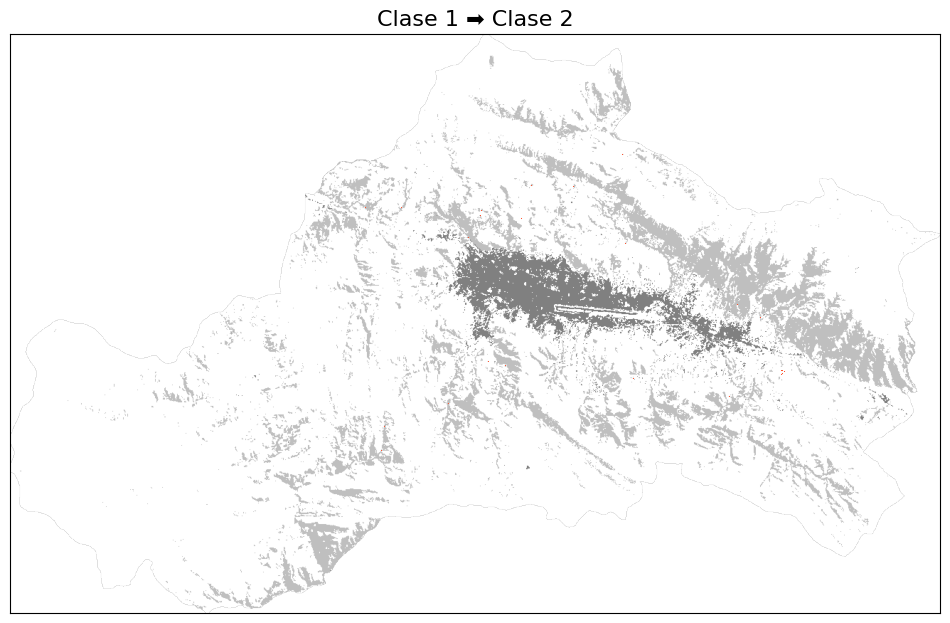

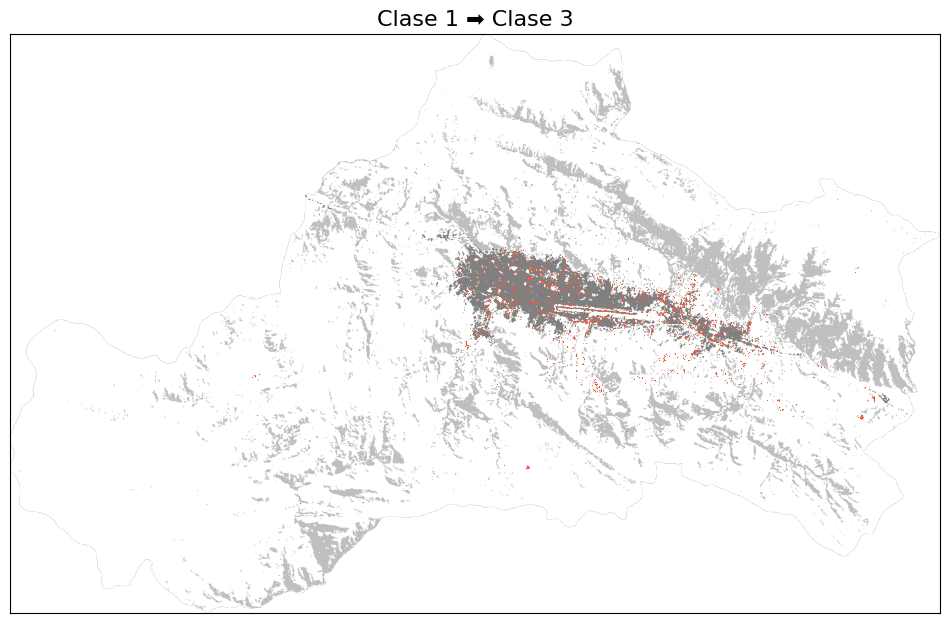

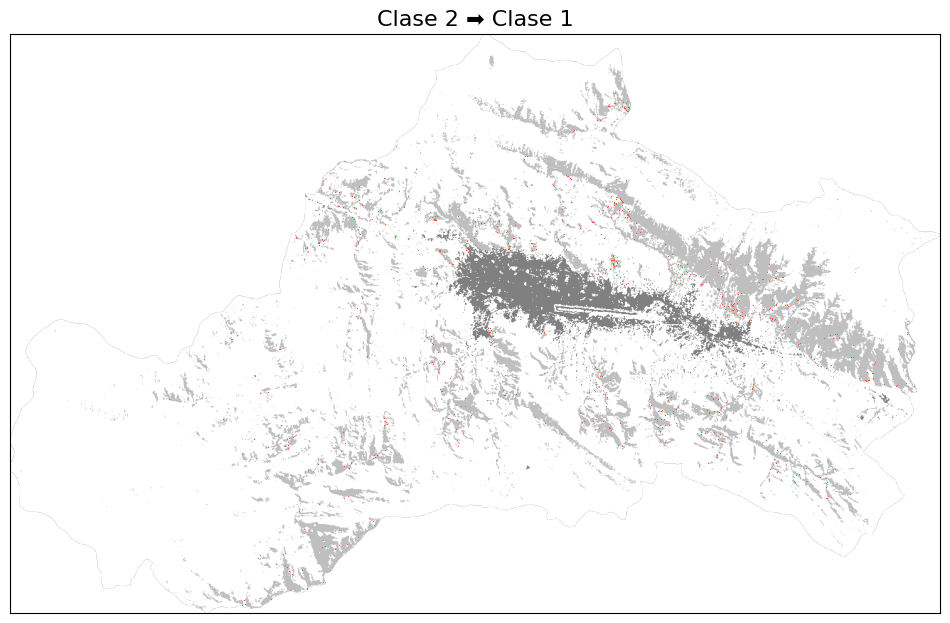

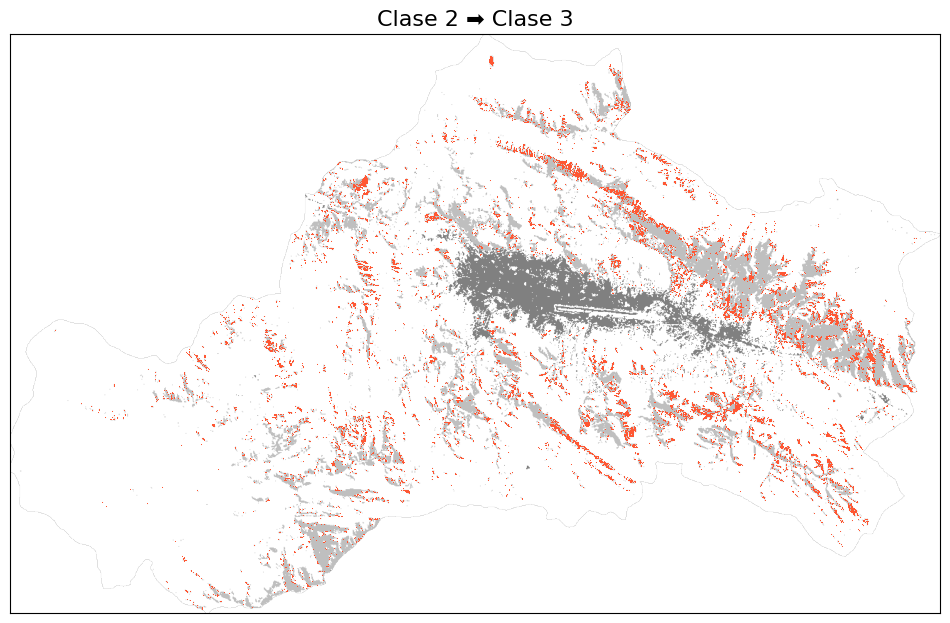

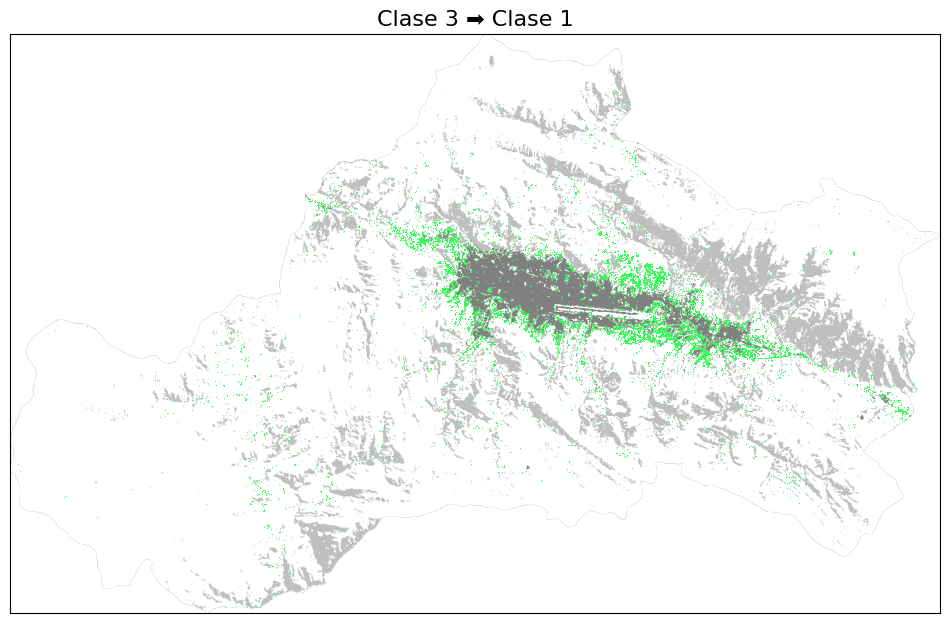

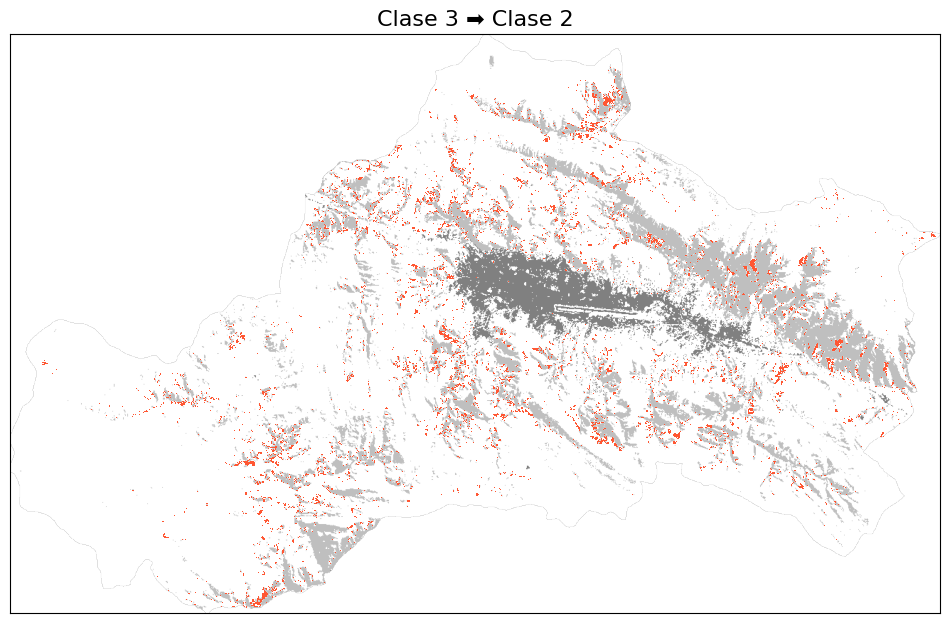

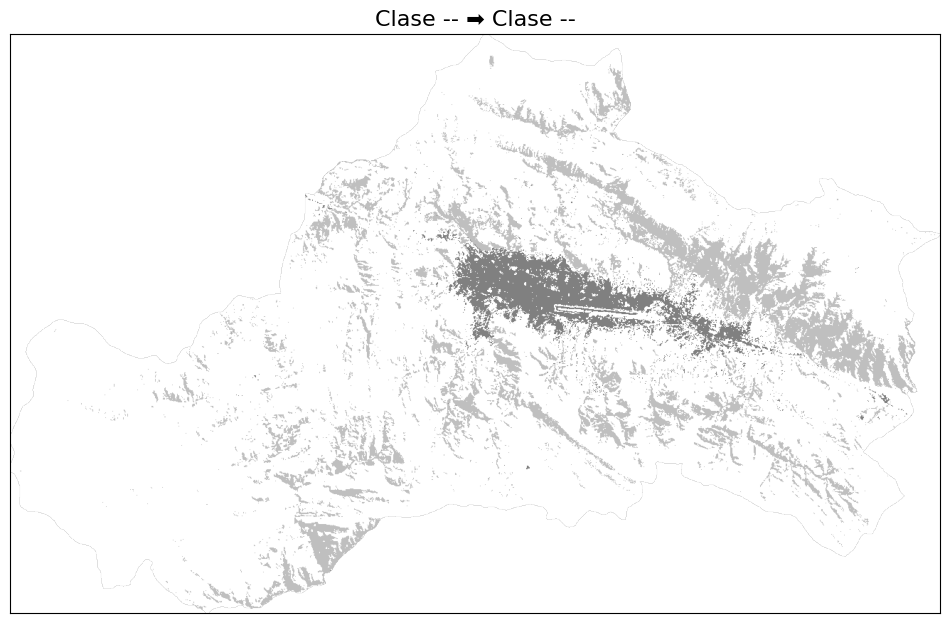

In [ ]:
# Land cover change map 2004 - 2014
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

print("---  Visualizando Transiciones de Cobertura en Gráficos Separados ---")

try:
    # --- Parte 1: Generar un mapa codificado de los cambios (sin cambios) ---

    if 'anho_2004' not in locals() or 'anho_2014' not in locals():
        raise NameError("Parece que 'initial_raster' o 'final_raster' no existen. Asegúrate de haber ejecutado la Celda 5.")

    print(f"Comparando cambios entre '{anho_2004.filename.split('/')[-1]}' y '{anho_2014.filename.split('/')[-1]}'")

    mapa_inicial_array = anho_2004.getBand(1)
    mapa_final_array = anho_2014.getBand(1)
    mascara_comun = mapa_inicial_array.mask | mapa_final_array.mask
    mapa_de_cambios_array = np.zeros_like(mapa_inicial_array, dtype=np.int16)
    indices_cambio = (~mascara_comun) & (mapa_inicial_array != mapa_final_array)
    clase_inicial = mapa_inicial_array[indices_cambio]
    clase_final = mapa_final_array[indices_cambio]
    codigo_cambio = clase_inicial * 10 + clase_final
    mapa_de_cambios_array[indices_cambio] = codigo_cambio

    # --- Parte 2: Visualizar cada cambio en un GRÁFICO SEPARADO ---

    codigos_de_cambio = np.unique(mapa_de_cambios_array)
    codigos_de_cambio = codigos_de_cambio[codigos_de_cambio != 0]

    if len(codigos_de_cambio) > 0:
        print(f"\nSe encontraron {len(codigos_de_cambio)} tipos de transiciones. Generando gráficos separados...")

        colores_resaltantes = ['#FF5733', '#FF5733', '#FF5733', '#FF5733', '#33FF57', '#FF5733', '#FF5733']

        # El bucle ahora creará una figura nueva en CADA iteración
        for i, codigo in enumerate(codigos_de_cambio):
            clase_ini = codigo // 10
            clase_fin = codigo % 10
            etiqueta = f"Clase {clase_ini}  Clase {clase_fin}"

            # --- Creación de una figura individual para este cambio ---
            fig, ax = plt.subplots(figsize=(12, 12)) # Un solo gráfico, no una grilla

            # 1. Mostrar el mapa inicial como fondo
            ax.imshow(mapa_inicial_array, cmap='gray', alpha=0.5)

            # 2. Superponer el cambio actual
            mapa_cambio_actual = (mapa_de_cambios_array == codigo)
            mapa_cambio_mascarado = np.ma.masked_where(mapa_cambio_actual == 0, mapa_cambio_actual)

            color_actual = colores_resaltantes[i % len(colores_resaltantes)]
            cmap_resaltante = ListedColormap([color_actual])

            ax.imshow(mapa_cambio_mascarado, cmap=cmap_resaltante, interpolation='nearest')

            ax.set_title(etiqueta, fontsize=16)
            ax.set_xticks([])
            ax.set_yticks([])

            plt.show()

    else:
        print("No se encontraron cambios entre los dos mapas.")

except Exception as e:
    print(f"\n!!!!!! OCURRIó UN ERROR !!!!!!")
    import traceback
    traceback.print_exc()

In [ ]:
import numpy as np
import pandas as pd

# Tu matriz de transición:
T = np.array([
    [20297,   40,   3140],
    [1406, 54386,  22677],
    [15639, 15357, 456107]
], dtype=float)

classes = [1, 2, 3]
S = np.eye(len(classes))

# Cálculo simétrico de similitud
for i in range(len(classes)):
    for j in range(len(classes)):
        if i != j:
            num = T[i, j] + T[j, i]
            den = T[i, i] + T[j, j] + T[i, j] + T[j, i]
            S[i, j] = num / den if den > 0 else 0

S_df = pd.DataFrame(S, index=classes, columns=classes)
print("Matriz de similitud difusa derivada de los datos históricos:")
print(S_df.round(3))


In [ ]:
# Cell 9: Evaluation with Spatial Fuzzy Kappa

import numpy as np
from scipy.ndimage import distance_transform_edt

def fuzzy_similarity_matrix(classes, confusion_tolerance=0.2):
    """
    Crea una matriz de similitud difusa entre clases (semántica o conceptual).
    En tu caso (1=Urbano, 2=Vegetación, 3=Suelo desnudo),
    podrías decir que Urbano y Suelo son parcialmente similares.
    """
    n = len(classes)
    S = np.eye(n)
    # Ejemplo: urbano (1) y suelo desnudo (3) tienen similitud 0.7
    for i, ci in enumerate(classes):
        for j, cj in enumerate(classes):
            if {ci, cj} == {1, 3}:
                S[i, j] = 0.7
    return S


def spatial_fuzzy_kappa(raster_ref, raster_sim, neighbourhood=1, similarity_matrix=None):
    """
    Calcula el Fuzzy Kappa Espacial entre dos mapas categóricos.
    """
    ref = raster_ref.getBand(1).filled(-9999)
    sim = raster_sim.getBand(1).filled(-9999)
    mask = (ref != -9999) & (sim != -9999)
    ref = ref[mask]
    sim = sim[mask]

    classes = np.unique(np.concatenate([ref, sim]))
    n_classes = len(classes)
    map_idx = {c: i for i, c in enumerate(classes)}
    if similarity_matrix is None:
        similarity_matrix = np.eye(n_classes)

    # --- Fuzzy membership espacial (ventanas de vecindad) ---
    ref_maps = np.zeros((n_classes, *raster_ref.getBand(1).shape))
    sim_maps = np.zeros_like(ref_maps)
    for i, c in enumerate(classes):
        ref_mask = (raster_ref.getBand(1).filled(0) == c).astype(np.uint8)
        sim_mask = (raster_sim.getBand(1).filled(0) == c).astype(np.uint8)
        ref_maps[i] = np.exp(-distance_transform_edt(1 - ref_mask) / neighbourhood)
        sim_maps[i] = np.exp(-distance_transform_edt(1 - sim_mask) / neighbourhood)

    # --- Similaridad fuzzy pixel a pixel ---
    num = np.zeros_like(ref_maps[0])
    den = np.zeros_like(ref_maps[0])
    for i in range(n_classes):
        for j in range(n_classes):
            num += similarity_matrix[i, j] * ref_maps[i] * sim_maps[j]
            den += ref_maps[i] * sim_maps[j]

    fuzzy_agreement = np.sum(num) / np.sum(den)

    # --- Kappa fuzzy ---
    # Probabilidad esperada (acuerdo aleatorio)
    p_ref = np.mean(ref_maps, axis=(1, 2))
    p_sim = np.mean(sim_maps, axis=(1, 2))
    expected_agreement = np.sum(p_ref[:, None] * p_sim[None, :] * similarity_matrix)

    fuzzy_kappa = (fuzzy_agreement - expected_agreement) / (1 - expected_agreement)
    return fuzzy_kappa


# === EJECUCIÓN ===

print("\n======================================================================")
print(" FASE 2: Evaluación del Modelo con Fuzzy Kappa Espacial ")
print("======================================================================")

classes = [1, 2, 3]
S = S_df.values  # la matriz empírica derivada de tus datos

kappa_fuzzy_spatial = spatial_fuzzy_kappa(anho_2024, predicted_raster_validacion, neighbourhood=1, similarity_matrix=S)

print(f" Fuzzy Kappa Espacial (vecindad=1): {kappa_fuzzy_spatial:.3f}")


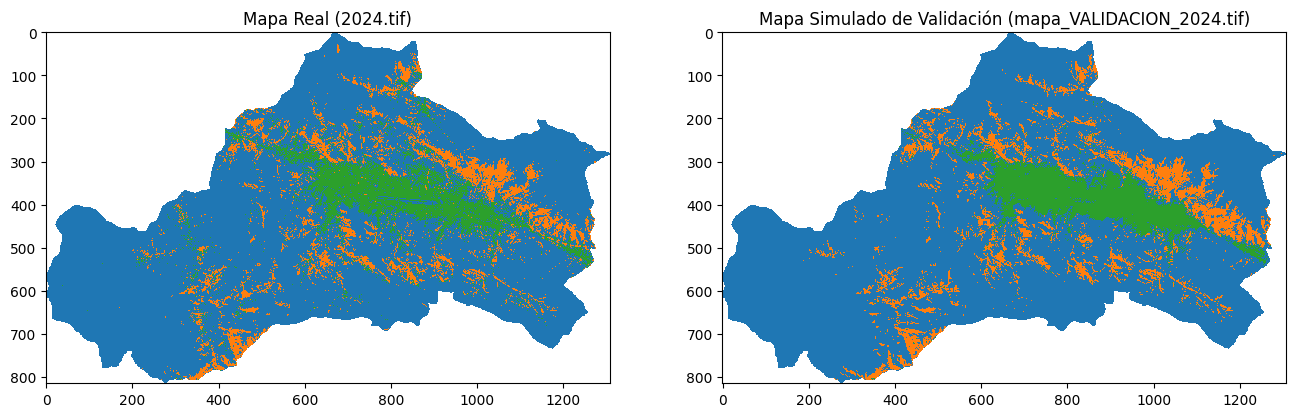

In [ ]:
# Cell 7: Phase 1C - Comparación y Métricas de Validación
from sklearn.metrics import confusion_matrix, cohen_kappa_score, f1_score, balanced_accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

try:
    print("======================================================================")
    print(" FASE 1C: MÉTRICAS DE VALIDACIÓN (REAL 2024 vs. SIMULADO 2024) ")
    print("======================================================================")

    if 'predicted_raster_validacion' not in locals():
        raise NameError("No se encontró el mapa de validación. Ejecuta la celda anterior.")

    # --- DATA PREPARATION ---
    real_array = anho_2024.getBand(1)
    predicted_array = predicted_raster_validacion.getBand(1)

    # Aplanar y filtrar valores NoData
    mascara_comun = real_array.mask | predicted_array.mask
    real_validos = real_array.data[~mascara_comun]
    predicted_validos = predicted_array.data[~mascara_comun]

    # --- CÁLCULO DE MÉTRICAS ---
    print("\n--- Métricas de Precisión del Modelo ---")
    certeza_general = accuracy_score(real_validos, predicted_validos)
    kappa = cohen_kappa_score(real_validos, predicted_validos)

    print(f"Certeza General (Overall Accuracy): {certeza_general:.4f} ({certeza_general:.2%})")
    print(f"Coeficiente Kappa: {kappa:.4f}")
    if kappa > 0.8:
        print("Resultado: Excelente concordancia.  El modelo es confiable.")
    elif kappa > 0.6:
        print("Resultado: Buena concordancia.  El modelo es aceptable.")
    else:
        print("Resultado: Concordancia moderada o baja.  Revisa los parámetros o factores.")
    print("-" * 60)

    # --- VISUALIZACIÓN COMPARATIVA ---
    print("--- Comparación Visual: Mapa Real vs. Mapa Simulado ---")
    clases = crosstable_entrenamiento.graduation_x
    colores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd']
    cmap_discreto = ListedColormap(colores[:len(clases)])
    bounds = [c - 0.5 for c in clases] + [clases[-1] + 0.5]
    norm = BoundaryNorm(bounds, cmap_discreto.N)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    ax1.imshow(real_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax1.set_title(f'Mapa Real ({os.path.basename(rutas["anho_2024"])})')
    ax2.imshow(predicted_array, cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax2.set_title(f'Mapa Simulado de Validación ({os.path.basename(rutas["salida_validacion"])})')
    plt.show()

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA VALIDACIÓN FINAL !!!!!!")
    import traceback
    traceback.print_exc()

In [ ]:
# Cell 6: Class for Advanced Multiscale Validation
import pandas as pd
import scipy.ndimage as ndi

class ValidationMultiScale:
    """
    Implementa una validación multiescala que combina el Coeficiente Kappa
    con el análisis de "presupuesto de error" de Pontius Jr. et al. (2004).

    Esta clase calcula cómo cambian Kappa y otras métricas de concordancia
    a medida que los mapas de referencia y simulado se analizan a resoluciones
    progresivamente más gruesas.
    """
    def __init__(self, reference_raster, simulated_raster):
        print("Inicializando validador multiescala...")
        if not reference_raster.geoDataMatch(simulated_raster):
            raise ValueError("Los rásters de referencia y simulado no coinciden en geometría.")

        # Extraer solo las bandas y máscaras necesarias
        self.ref_map = reference_raster.getBand(1)
        self.sim_map = simulated_raster.getBand(1)

        # Unificar la máscara para asegurar la comparación de píxeles válidos en ambos mapas
        common_mask = self.ref_map.mask | self.sim_map.mask
        self.ref_map.mask = common_mask
        self.sim_map.mask = common_mask

        # Obtener categorías y forma inicial
        self.categories = sorted(list(set(np.unique(self.ref_map.compressed())) | set(np.unique(self.sim_map.compressed()))))
        self.initial_shape = self.ref_map.shape
        print(f"Validación lista para mapas de {self.initial_shape} con clases: {self.categories}")


    def _coarsen_map(self, data_map, scale):
        """
        Reduce la resolución de un mapa promediando los valores de clase
        dentro de ventanas de 'scale x scale'. Es un proceso complejo.
        Esta es una implementación simplificada que usa el remuestreo por vecino más cercano
        para mantener los valores de clase discretos.
        """
        zoom_factor = 1 / scale
        # Remuestrear los datos y la máscara por separado
        coarse_data = ndi.zoom(data_map.data, zoom_factor, order=0) # order=0 es vecino más cercano
        coarse_mask = ndi.zoom(data_map.mask, zoom_factor, order=0, output=bool)
        return ma.array(coarse_data, mask=coarse_mask)


    def _calculate_kappa(self, ref_array, sim_array):
        """Calcula el Coeficiente Kappa a partir de dos arrays enmascarados."""
        ct = CrossTable(ref_array, sim_array, expand=True)
        conf_matrix = ct.getCrosstable()

        n = np.sum(conf_matrix)
        if n == 0: return 0.0

        po = np.trace(conf_matrix) / n  # Concordancia observada
        sum_rows = np.sum(conf_matrix, axis=1)
        sum_cols = np.sum(conf_matrix, axis=0)
        pe = np.sum(sum_rows * sum_cols) / (n * n) # Concordancia esperada por azar

        if pe == 1: return 1.0
        return (po - pe) / (1 - pe)

    def _calculate_budget_metrics(self, ref_array, sim_array):
        """Calcula las métricas del 'error budget'."""
        # Preparar mapas de proporción para cada categoría
        Rj, Sj = {}, {}
        for j in self.categories:
            Rj[j] = (ref_array == j).astype(float)
            Sj[j] = (sim_array == j).astype(float)

        W = ~ref_array.mask.astype(int) # Pesos (1 para píxeles válidos, 0 para enmascarados)
        sum_W = np.sum(W)
        if sum_W == 0: return {'NoMed': 0, 'MedMed': 0}

        # Medium information about quantity, medium information about location (Concordancia real)
        med_med_arr = np.zeros_like(ref_array, dtype=float)
        for j in self.categories:
            med_med_arr += np.minimum(Rj[j], Sj[j])
        MedMed = np.sum(W * med_med_arr) / sum_W

        # No information about quantity, medium information about location
        no_med_arr = np.zeros_like(ref_array, dtype=float)
        for j in self.categories:
            S_total_prop = np.sum(W * Sj[j]) / sum_W
            no_med_arr += np.minimum(Rj[j], S_total_prop)
        NoMed = np.sum(W * no_med_arr) / sum_W

        return {'NoMed': NoMed, 'MedMed': MedMed}

    def run_analysis(self, iterations=5, scale_factor=2):
        """
        Ejecuta el análisis multiescala.

        Args:
            iterations (int): Número de niveles de escala a analizar.
            scale_factor (int): Factor por el cual se reduce la resolución en cada iteración.
        """
        print(f"\n Iniciando análisis multiescala con {iterations} iteraciones...")
        results = []

        current_ref_map = self.ref_map
        current_sim_map = self.sim_map

        for i in range(iterations):
            scale = scale_factor ** i
            print(f" -> Iteración {i+1}/{iterations} (Escala: {scale}x)")

            # Calcular métricas para la escala actual
            kappa = self._calculate_kappa(current_ref_map, current_sim_map)
            budget = self._calculate_budget_metrics(current_ref_map, current_sim_map)

            results.append({
                'Iteración': i,
                'Escala': scale,
                'Kappa': kappa,
                'Acuerdo por Cantidad (NoMed)': budget['NoMed'],
                'Acuerdo Total (MedMed)': budget['MedMed']
            })

            # Preparar la siguiente iteración si no es la última
            if i < iterations - 1:
                current_ref_map = self._coarsen_map(current_ref_map, scale_factor)
                current_sim_map = self._coarsen_map(current_sim_map, scale_factor)

        print(" Análisis multiescala completado.")
        return pd.DataFrame(results)

print("Clase 'ValidationMultiScale' cargada y lista para usar.")

In [ ]:
# Celda 2B: Function for Fuzzy Accuracy Calculation (Fuzzy Accuracy)
import scipy.ndimage as ndi

def calcular_precision_difusa(mapa_real, mapa_predicho, tamano_ventana=1):
    """
    Calcula la precisión difusa comparando cada píxel predicho con una
    vecindad o 'buffer' alrededor del píxel correspondiente en el mapa real.

    Args:
        mapa_real (np.ma.array): El array enmascarado del mapa de referencia (la verdad).
        mapa_predicho (np.ma.array): El array enmascarado del mapa simulado.
        tamano_ventana (int): El radio de la vecindad para la comparación.
                                 1 = vecindad de 3x3
                                 2 = vecindad de 5x5

    Returns:
        float: El puntaje de precisión difusa (de 0.0 a 1.0).
    """
    print(f"\n---  Calculando Precisión Difusa con ventana de {2*tamano_ventana+1}x{2*tamano_ventana+1} ---")

    # Asegurarnos de trabajar con los mismos píxeles válidos en ambos mapas
    mascara_comun = mapa_real.mask | mapa_predicho.mask
    real_validos = np.ma.array(mapa_real.data, mask=mascara_comun)
    pred_validos = np.ma.array(mapa_predicho.data, mask=mascara_comun)

    # Obtener todas las clases presentes en los mapas
    clases = np.unique(real_validos.compressed())

    # Crear una estructura para la operación de dilatación (define la forma de la vecindad)
    estructura_vecindad = ndi.generate_binary_structure(2, 1) # Vecindad de 8 conexiones

    # Inicializar un mapa de aciertos
    mapa_de_aciertos = np.zeros_like(real_validos.data, dtype=bool)

    # Iterar por cada clase para crear su "mapa de verdad difuso"
    for clase_actual in clases:
        # 1. Crear un mapa binario para la clase actual en el mapa real
        mapa_real_binario = (real_validos.data == clase_actual)

        # 2. "Engrosar" o "Dilatar" la verdad en 1 píxel.
        #    Esto crea un buffer donde una predicción se considera correcta.
        mapa_verdad_difuso = ndi.binary_dilation(mapa_real_binario, structure=estructura_vecindad, iterations=tamano_ventana)

        # 3. Identificar dónde el mapa predicho coincide con la verdad difusa
        prediccion_coincide_con_clase = (pred_validos.data == clase_actual)

        # 4. Marcar estos píxeles como aciertos
        #    Un acierto ocurre si la predicción es la clase actual Y esa ubicación
        #    está dentro del buffer de la verdad para esa misma clase.
        aciertos_para_clase = prediccion_coincide_con_clase & mapa_verdad_difuso

        mapa_de_aciertos = mapa_de_aciertos | aciertos_para_clase

    # 5. Calcular la precisión final
    total_pixeles_validos = np.sum(~mascara_comun)
    total_aciertos_difusos = np.sum(mapa_de_aciertos)

    precision_difusa = total_aciertos_difusos / total_pixeles_validos if total_pixeles_validos > 0 else 0

    print(f"Píxeles correctamente predichos (con margen de error): {total_aciertos_difusos}")
    print(f"Total de píxeles válidos para comparación: {total_pixeles_validos}")

    return precision_difusa

print("Función 'calcular_precision_difusa' cargada y lista.")

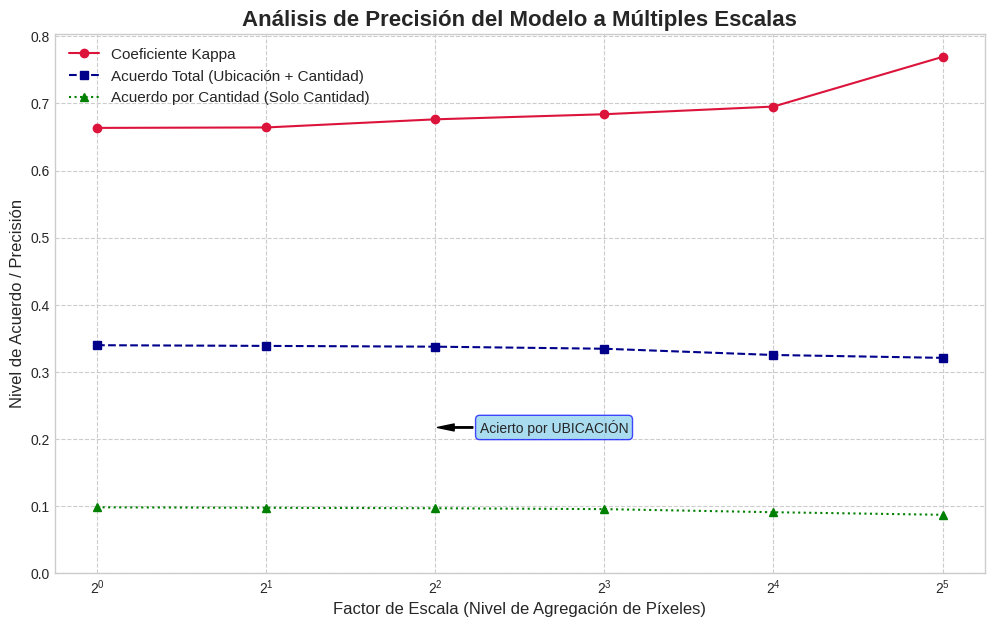

In [ ]:
# Celda 7B: Phase 1D - Advanced Multiscale Validation
try:
    print("\n======================================================================")
    print(" FASE 1D: VALIDACIÓN MULTIESCALA (KAPPA & ERROR BUDGET) ")
    print("======================================================================")

    # 1. Crear una instancia del validador con el mapa real y el simulado
    validator = ValidationMultiScale(anho_2024, predicted_raster_validacion)

    # 2. Ejecutar el análisis con 6 iteraciones. En cada una, la resolución se reduce a la mitad.
    #    Escalas analizadas: 1x1, 2x2, 4x4, 8x8, 16x16, 32x32
    validation_results_df = validator.run_analysis(iterations=6, scale_factor=2)


    # --- VISUALIZACIÓN DE RESULTADOS ---
    print("\n--- Resultados de la Validación Multiescala ---")
    print(validation_results_df.to_string(index=False, float_format="%.4f"))

    # --- GRÁFICO DE RESULTADOS ---
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(12, 7))

    ax.plot(validation_results_df['Escala'], validation_results_df['Kappa'],
            marker='o', linestyle='-', color='crimson', label='Coeficiente Kappa')
    ax.plot(validation_results_df['Escala'], validation_results_df['Acuerdo Total (MedMed)'],
            marker='s', linestyle='--', color='darkblue', label='Acuerdo Total (Ubicación + Cantidad)')
    ax.plot(validation_results_df['Escala'], validation_results_df['Acuerdo por Cantidad (NoMed)'],
            marker='^', linestyle=':', color='green', label='Acuerdo por Cantidad (Solo Cantidad)')

    # --- ANOTACIONES Y ESTILO DEL GRÁFICO ---
    ax.set_title('Análisis de Precisión del Modelo a Múltiples Escalas', fontsize=16, weight='bold')
    ax.set_xlabel('Factor de Escala (Nivel de Agregación de Píxeles)', fontsize=12)
    ax.set_ylabel('Nivel de Acuerdo / Precisión', fontsize=12)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=11)
    ax.set_xscale('log', base=2) # La escala logarítmica es ideal para este análisis
    ax.grid(True, which="both", ls="--")

    # Anotar el espacio entre las curvas
    x_pos = validation_results_df['Escala'].iloc[2]
    y1 = validation_results_df['Acuerdo por Cantidad (NoMed)'].iloc[2]
    y2 = validation_results_df['Acuerdo Total (MedMed)'].iloc[2]
    ax.annotate('Acierto por UBICACIÓN', xy=(x_pos, y1 + (y2-y1)/2), xytext=(x_pos*1.2, y1 + (y2-y1)/2),
                arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
                ha='left', va='center', bbox=dict(boxstyle="round,pad=0.3", fc="skyblue", ec="b", lw=1, alpha=0.7))

    # ====================================================================
    #           NUEVA SECCIÓN PARA VALIDACIÓN DIFUSA
    # ====================================================================
    # Se llama a la función que definimos en la Celda 2B
    precision_difusa_3x3 = calcular_precision_difusa(real_array, predicted_array, tamano_ventana=1)

    print("\n--- Métrica de Precisión Difusa (con Vecindad) ---")
    print(f"Precisión Difusa (Fuzzy Accuracy con ventana 3x3): {precision_difusa_3x3:.4f} ({precision_difusa_3x3:.2%})")

    print("\n INTERPRETACIÓN:")
    print(f"La precisión aumentó de {certeza_general:.2%} a {precision_difusa_3x3:.2%} al permitir un margen de error de 1 píxel (30 metros).")
    diferencia = precision_difusa_3x3 - certeza_general
    print(f"Esta diferencia del {diferencia:.2%} representa los 'casi aciertos' del modelo, confirmando que predice bien los patrones generales.")
    print("-" * 60)

    plt.show()

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA VALIDACIÓN MULTIESCALA !!!!!!")
    import traceback
    traceback.print_exc()

In [ ]:
# Cell 7: Phase 1C - Comparación y Métricas de Validación

from sklearn.metrics import confusion_matrix, cohen_kappa_score, f1_score, balanced_accuracy_score, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import numpy as np
import pandas as pd

try:
    print("======================================================================")
    print(" FASE 1C: MÉTRICAS DE VALIDACIÓN (REAL 2024 vs. SIMULADO 2024) ")
    print("======================================================================")

    if 'predicted_raster_validacion' not in locals():
        raise NameError("No se encontró el mapa de validación. Ejecuta la celda anterior.")

    # --- DATA PREPARATION ---
    real_array = anho_2024.getBand(1)
    predicted_array = predicted_raster_validacion.getBand(1)

    # Aplanar y filtrar valores NoData
    mascara_comun = real_array.mask | predicted_array.mask
    real_validos = real_array.data[~mascara_comun]
    predicted_validos = predicted_array.data[~mascara_comun]

    # --- CÁLCULO DE MÉTRICAS ---
    print("\n--- Métricas de Precisión del Modelo ---")
    certeza_general = accuracy_score(real_validos, predicted_validos)
    kappa = cohen_kappa_score(real_validos, predicted_validos)

    print(f"Certeza General (Overall Accuracy): {certeza_general:.4f} ({certeza_general:.2%})")
    print(f"Coeficiente Kappa (General): {kappa:.4f}")

    if kappa > 0.8:
        print("Resultado: Excelente concordancia.  El modelo es confiable.")
    elif kappa > 0.6:
        print("Resultado: Buena concordancia.  El modelo es aceptable.")
    else:
        print("Resultado: Concordancia moderada o baja.  Revisa los parámetros o factores.")
    print("-" * 60)

    # --- MATRIZ DE CONFUSIÓN ---
    print("\n--- Matriz de Confusión ---")
    etiquetas = sorted(list(set(np.concatenate((real_validos, predicted_validos)))))
    conf_matrix = confusion_matrix(real_validos, predicted_validos, labels=etiquetas)
    conf_df = pd.DataFrame(conf_matrix, index=[f'Real_{l}' for l in etiquetas],
                           columns=[f'Pred_{l}' for l in etiquetas])
    print(conf_df)

    # --- CÁLCULO DETALLADO DE KAPPAS ---
    print("\n--- Desglose del Coeficiente Kappa ---")

    N = len(real_validos)
    Po = certeza_general

    # Convertimos a proporciones
    sum_real = conf_matrix.sum(axis=1) / N
    sum_pred = conf_matrix.sum(axis=0) / N

    Pe = np.sum(sum_real * sum_pred)
    P_quantity = np.sum(np.minimum(sum_real, sum_pred))

    # Kappas corregidos y validados
    Kstandard = (Po - Pe) / (1 - Pe) if (1 - Pe) != 0 else np.nan
    Khisto = (P_quantity - Pe) / (1 - Pe) if (1 - Pe) != 0 else np.nan

    if P_quantity >= 1 or Po < P_quantity:
        Kloc = np.nan
    else:
        Kloc = (Po - P_quantity) / (1 - P_quantity)

    print(f"Kappa General (Kstandard): {Kstandard:.4f}")
    print(f"Kappa de Histograma (Khisto): {Khisto:.4f}")
    print(f"Kappa de Localización (Kloc): {Kloc if not np.isnan(Kloc) else 'N/A'}")
    print("-" * 60)
    print(f"Po (acuerdo observado): {Po:.4f}")
    print(f"Pe (acuerdo esperado): {Pe:.4f}")
    print(f"P_quantity (acuerdo por cantidad): {P_quantity:.4f}")

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA VALIDACIÓN FINAL !!!!!!")
    import traceback
    traceback.print_exc()


In [ ]:
# Cell 7: Phase 1C - Comparación y Métricas de Validación
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import pandas as pd # Importar pandas para una mejor visualización de la matriz

try:
    print("======================================================================")
    print(" FASE 1C: MÉTRICAS DE VALIDACIÓN (REAL 2024 vs. SIMULADO 2024) ")
    print("======================================================================")

    if 'predicted_raster_validacion' not in locals():
        raise NameError("No se encontró el mapa de validación. Ejecuta la celda anterior.")

    # --- DATA PREPARATION ---
    real_array = anho_2024.getBand(1)
    predicted_array = predicted_raster_validacion.getBand(1)

    # Aplanar y filtrar valores NoData
    mascara_comun = real_array.mask | predicted_array.mask
    real_validos = real_array.data[~mascara_comun]
    predicted_validos = predicted_array.data[~mascara_comun]

    # --- CÁLCULO DE MÉTRICAS ---
    print("\n--- Métricas de Precisión del Modelo ---")
    certeza_general = accuracy_score(real_validos, predicted_validos)
    kappa_standard = cohen_kappa_score(real_validos, predicted_validos) # Kstandard

    print(f"Certeza General (Overall Accuracy): {certeza_general:.4f} ({certeza_general:.2%})")
    print(f"Coeficiente Kappa Estándar: {kappa_standard:.4f}")
    if kappa_standard > 0.8:
        print("Resultado: Excelente concordancia.  El modelo es confiable.")
    elif kappa_standard > 0.6:
        print("Resultado: Buena concordancia.  El modelo es aceptable.")
    else:
        print("Resultado: Concordancia moderada o baja.  Revisa los parámetros o factores.")
    print("-" * 60)

    # --- DESGLOSE AVANZADO DE KAPPA ---
    print("\n--- Desglose Avanzado del Coeficiente Kappa ---")
    # 1. Calcular la matriz de confusión
    labels = sorted(list(set(np.concatenate((predicted_validos, real_validos)))))
    conf_matrix = confusion_matrix(real_validos, predicted_validos, labels=labels)

    # 2. Calcular los componentes de Kappa
    N = len(real_validos)
    Po = certeza_general
    sum_real = conf_matrix.sum(axis=1) # Suma de filas (total real por clase)
    sum_pred = conf_matrix.sum(axis=0) # Suma de columnas (total predicho por clase)

    # Acuerdo esperado por azar (Pe)
    Pe = np.sum(sum_real * sum_pred) / (N**2)

    # Acuerdo en cantidad (Pquantity)
    P_quantity = np.sum(np.minimum(sum_real, sum_pred)) / N

    # 3. Calcular K_histo y K_loc, evitando división por cero
    Khisto = (P_quantity - Pe) / (1 - Pe) if (1 - Pe) != 0 else 0
    Kloc = (Po - P_quantity) / (1 - P_quantity) if (1 - P_quantity) != 0 else 0

    print(f"Kappa de Histograma (Khisto): {Khisto:.4f}")
    print(f" > Mide qué tan bien el modelo predice la CANTIDAD de píxeles de cada clase.")
    print(f"Kappa de Localización (Kloc): {Kloc:.4f}")
    print(f" > Mide qué tan bien el modelo predice la UBICACIÓN espacial de esas clases.")
    print("-" * 60)

    # --- MATRIZ DE CONFUSIÓN DETALLADA ---
    print("\n--- Matriz de Confusión ---")
    conf_matrix_df = pd.DataFrame(conf_matrix,
                                  index=[f'Real_{l}' for l in labels],
                                  columns=[f'Pred_{l}' for l in labels])
    print(conf_matrix_df)

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA VALIDACIÓN FINAL !!!!!!")
    import traceback
    traceback.print_exc()

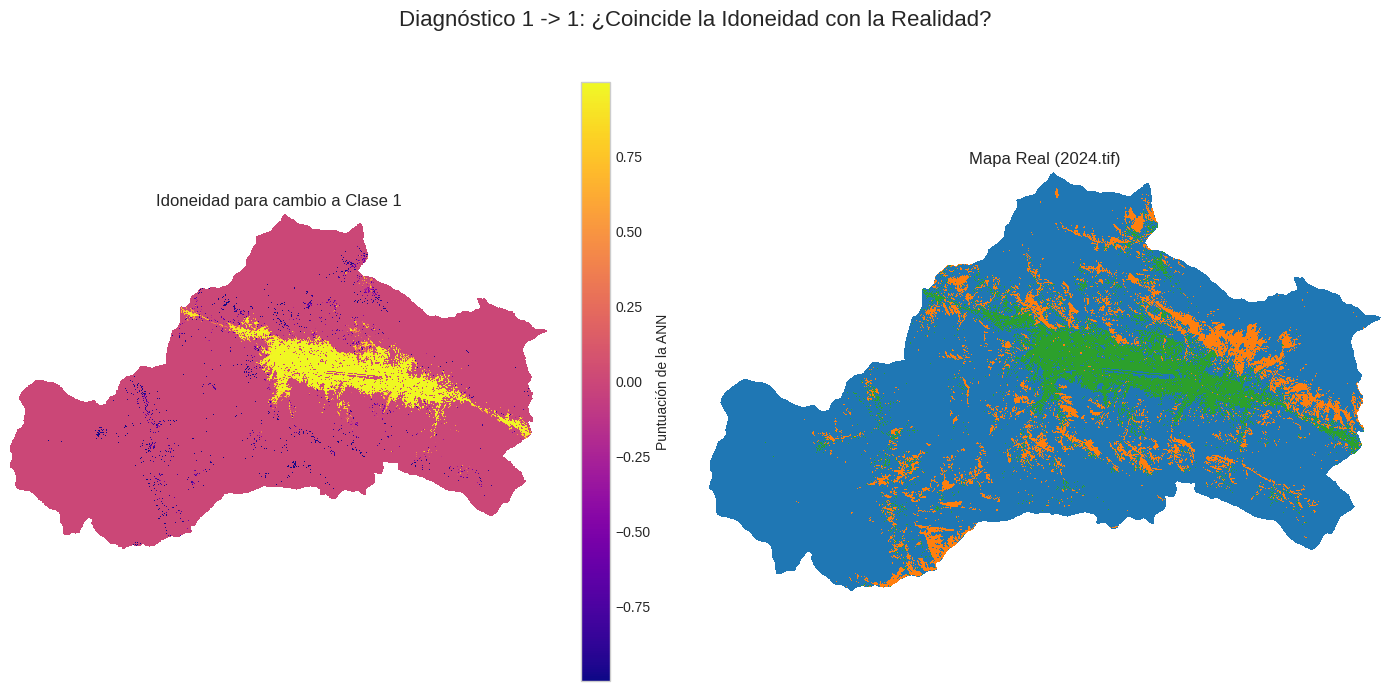

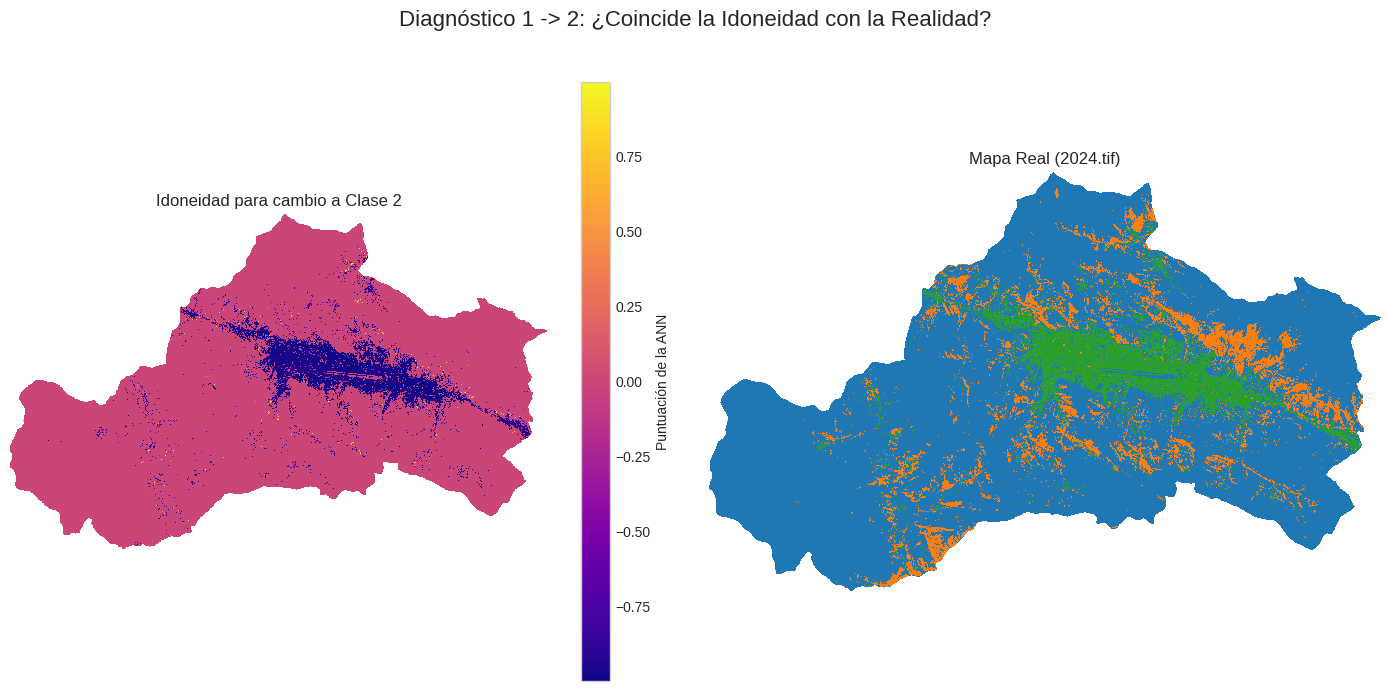

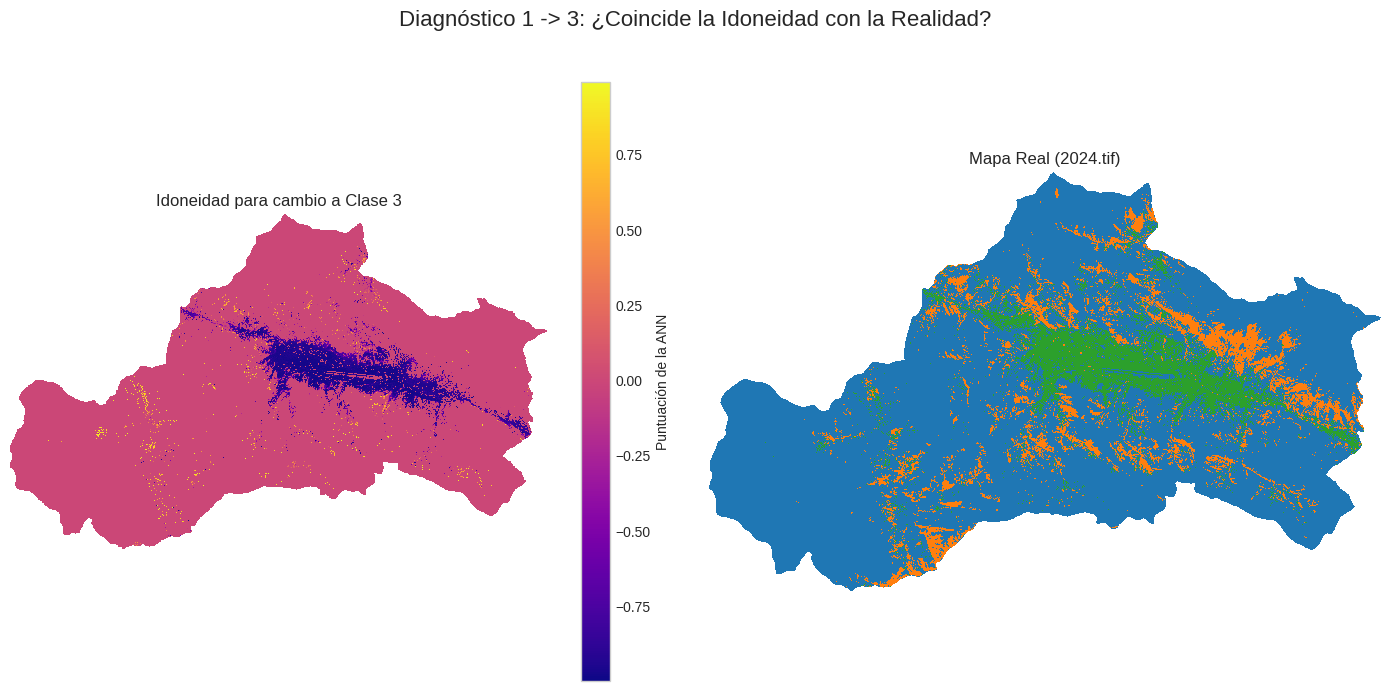

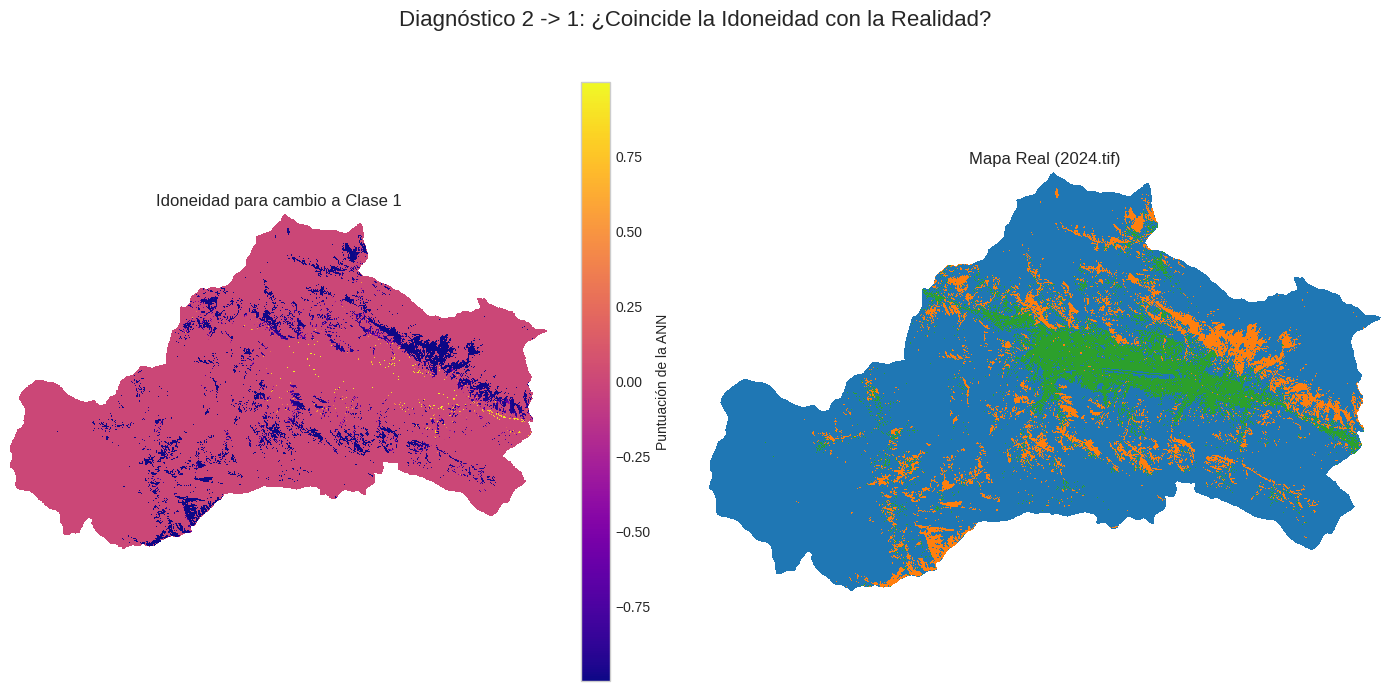

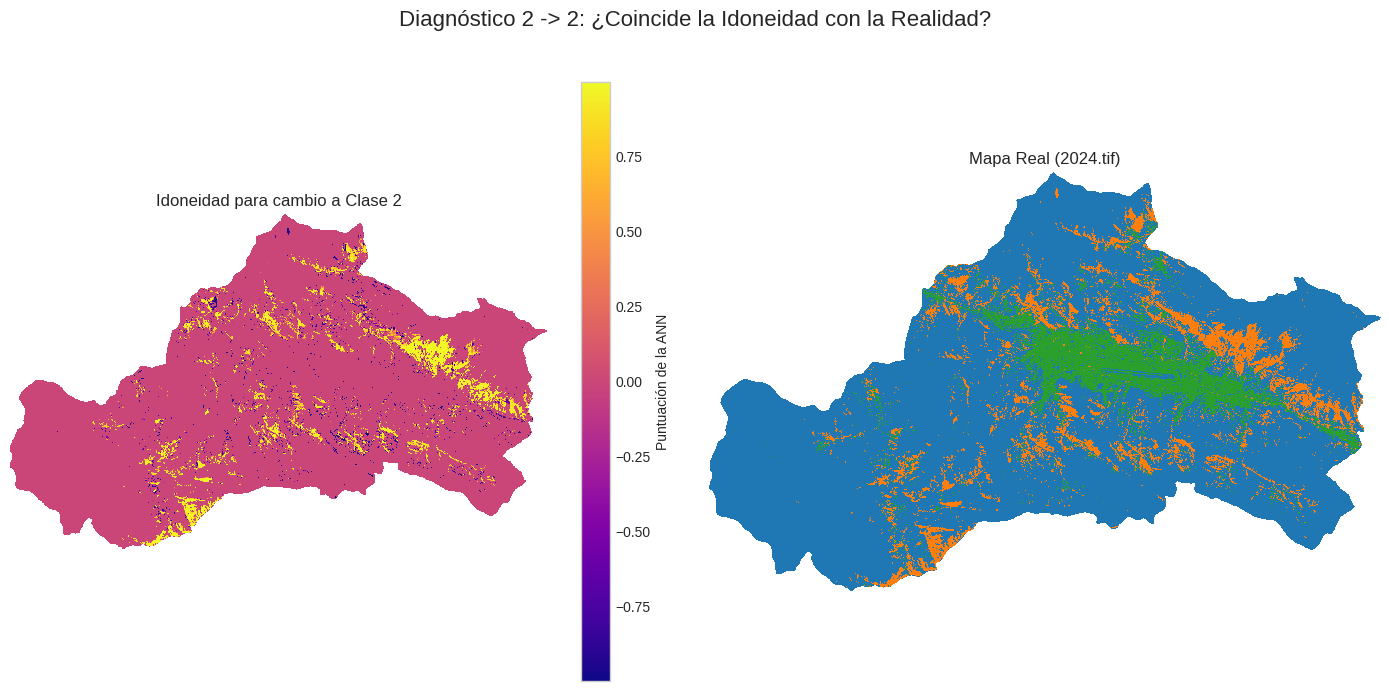

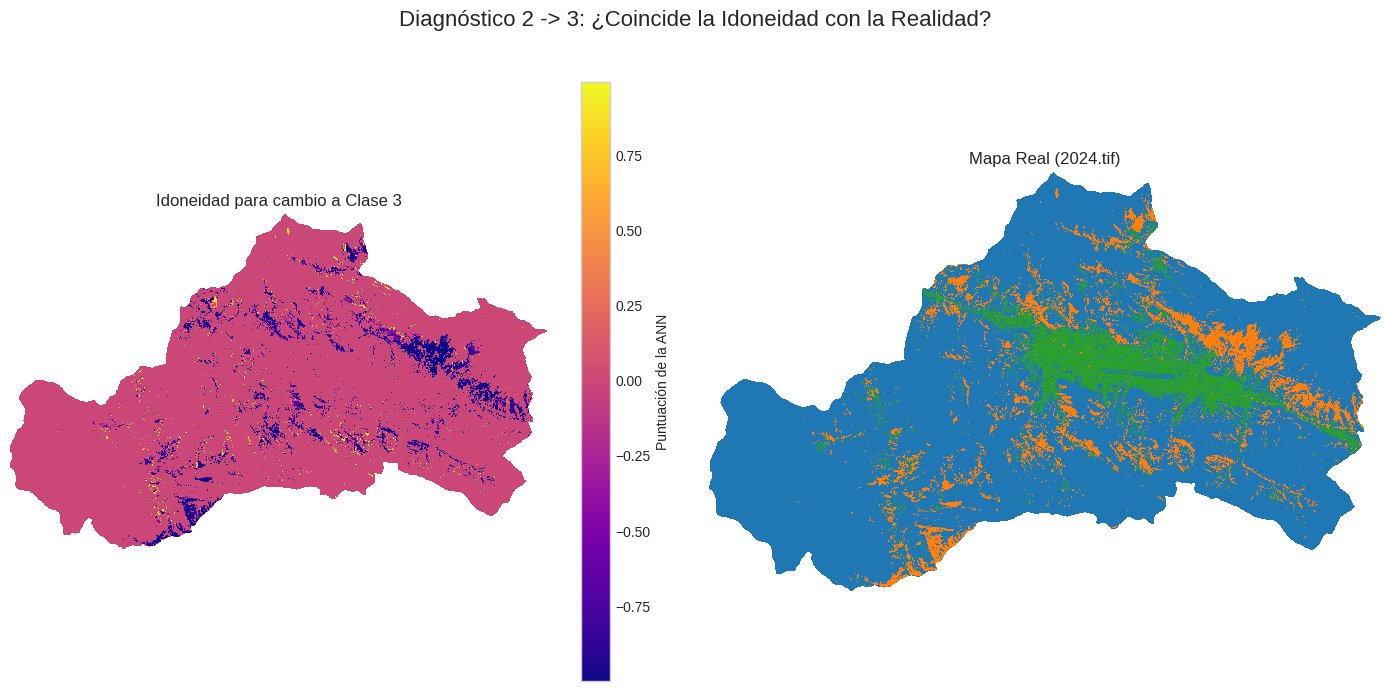

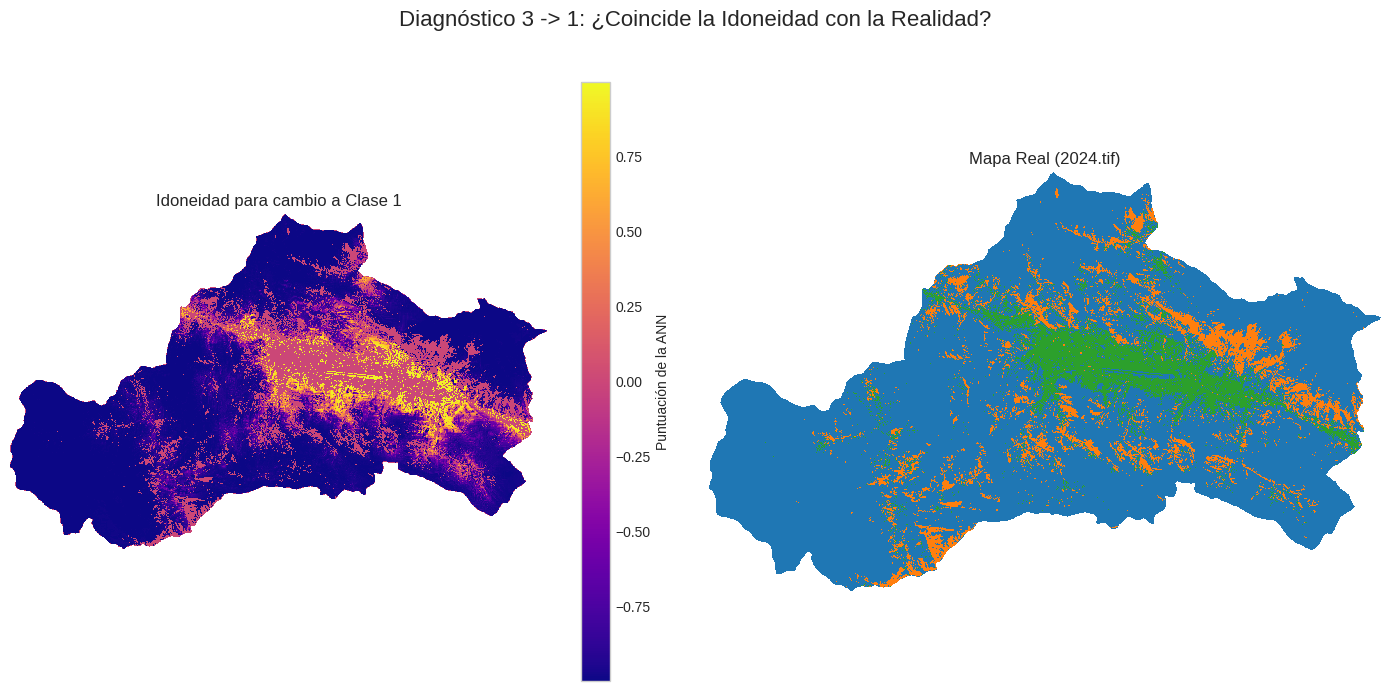

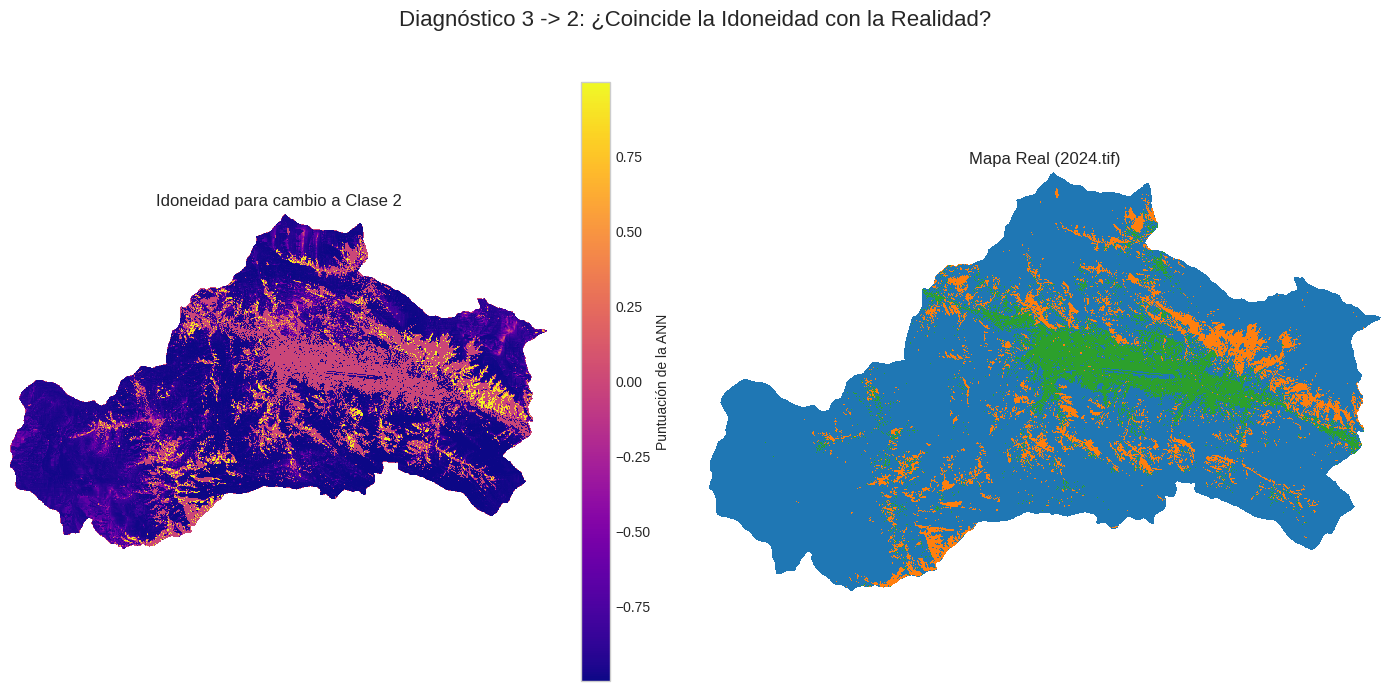

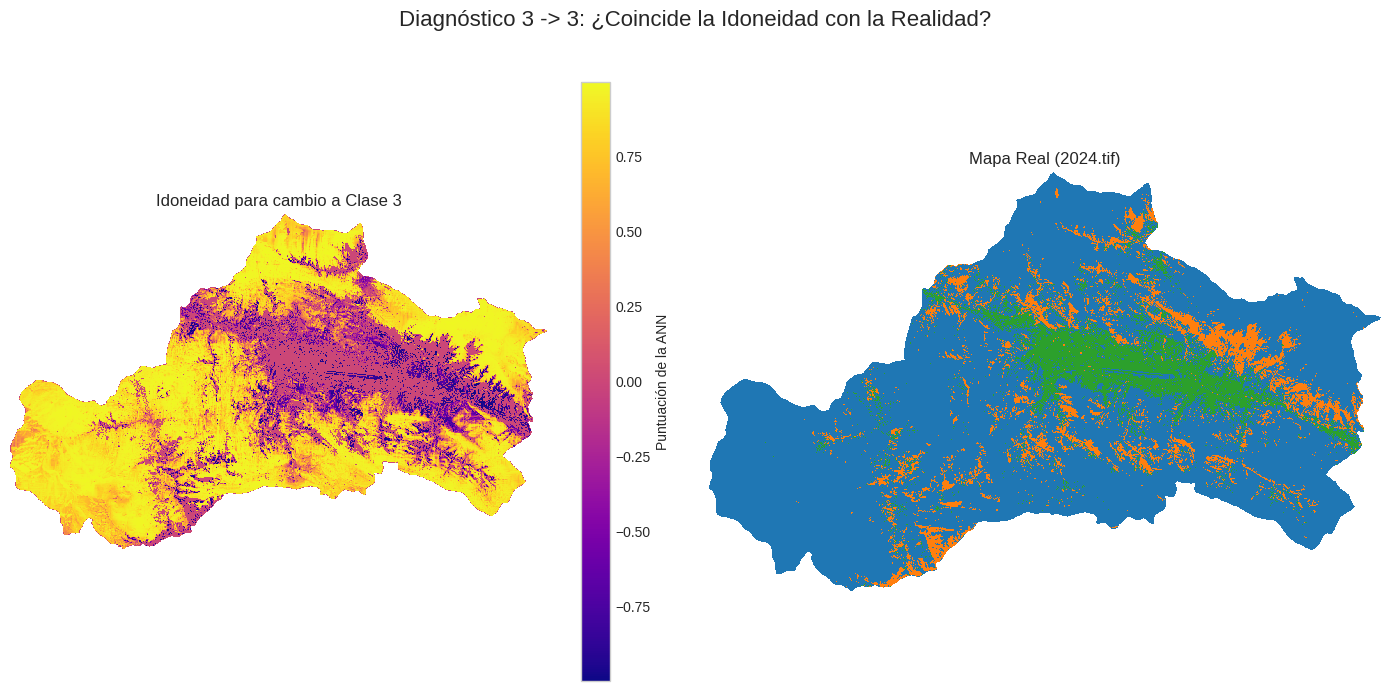

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
# Assuming that 'Raster' is a class defined in your environment (for example, from pycax).
# from pycax.raster import Raster # Descomenta si usas pycax

print("--- ANÁLISIS VISUAL DE LA PREDICCIÓN (TODAS LAS TRANSICIONES) ---")

# Las clases van de 1 a 3.
clases = range(1, 4)

# Bucle sobre todas las clases de origen
for clase_origen_a_inspeccionar in clases:
    # Bucle sobre todas las clases de destino
    for clase_destino_a_inspeccionar in clases:

        # Opcional: Saltar la transición a sí mismo (clase_origen -> misma clase_destino),
        # ya que el mapa de idoneidad para "permanecer" a menudo no es el foco del análisis.
        # if clase_origen_a_inspeccionar == clase_destino_a_inspeccionar:
        #     continue

        print(f"\n====================================================")
        print(f"ANÁLISIS DE TRANSICIÓN: {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}")
        print(f"====================================================")

        try:
            # 1. Preparar el mapa de idoneidad para la transición seleccionada
            print(f"Generando mapa de idoneidad para la transición {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}...")

            # El mapa de potencial relevante
            # ¡ADVERTENCIA! Se asume que potential_maps_validacion[clase_destino_a_inspeccionar] exists.
            mapa_de_potencial = potential_maps_validacion[clase_destino_a_inspeccionar]

            # El mapa de idoneidad solo debe mostrar valores para los píxeles que eran la clase de origen en el mapa de partida (2014)
            # ¡ADVERTENCIA! Se asume que anho_3 está definido y tiene el método getBand(1).
            mapa_de_partida_array = anho_2024.getBand(1)
            candidate_pixels_mask = (mapa_de_partida_array.data == clase_origen_a_inspeccionar)

            suitability_map = mapa_de_potencial * candidate_pixels_mask
            suitability_map[mapa_de_partida_array.mask] = np.nan # Usar NaN para NoData para que se vea transparente

            # 2. Cargar el mapa real de 2024
            # ¡ADVERTENCIA! Se asume que 'Raster', 'rutas', 'cmap_discreto', y 'norm' están definidos.
            if 'real_2024_raster' not in locals():
                real_2024_raster = Raster(rutas["anho_2024"])
            real_2024_data = real_2024_raster.getBand(1)

            # --- GRÁFICO: Idoneidad vs. Mapa Real 2024 ---
            print("Mostrando Gráfico: Idoneidad vs. Realidad")
            fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
            fig1.suptitle(f'Diagnóstico {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}: ¿Coincide la Idoneidad con la Realidad?', fontsize=16)

            # Gráfico 1a: Mapa de Idoneidad
            im1 = ax1.imshow(suitability_map, cmap='plasma', interpolation='nearest')
            ax1.set_title(f'Idoneidad para cambio a Clase {clase_destino_a_inspeccionar}')
            ax1.axis('off')
            fig1.colorbar(im1, ax=ax1, label='Puntuación de la ANN')

            # Gráfico 1b: Mapa Real 2024
            ax2.imshow(real_2024_data, cmap=cmap_discreto, norm=norm, interpolation='nearest')
            ax2.set_title(f'Mapa Real ({os.path.basename(rutas["anho_2024"])})')
            ax2.axis('off')

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show() # Muestra el gráfico y pasa a la siguiente iteración.

        except KeyError as e:
            print(f"\n!!!!! ERROR: La clave {e} no se encontró en el diccionario 'potential_maps_validacion'. Asegúrate de que existe el mapa de potencial para la clase {clase_destino_a_inspeccionar}.")
            # Se imprime el traceback completo en el error genérico
        except Exception as e:
            print(f"\n!!!!!! OCURRIÓ UN ERROR DURANTE LA VISUALIZACIÓN DE DIAGNÓSTICO para {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}!!!!!!")
            import traceback
            traceback.print_exc()

In [ ]:
# Cell 11: Phase 2A - Preparation for Projection (CORRECTED)
try:
    print("\n======================================================================")
    print(" FASE 2A: PREPARANDO PARA LA PROYECCIÓN A FUTURO ")
    print("======================================================================")

    # --- PASO 1: MATRIZ DE TRANSICIÓN MÁS RECIENTE ---
    print("\nCalculando Matriz de Transición para la Proyección (2014 -> 2024)...")
    crosstable_proyeccion = CrossTable(anho_2014.getBand(1), anho_2024.getBand(1), expand=True)
    print("Matriz de demanda de cambio para el futuro calculada. ")

    # --- PASO 2: PREPARAR FACTORES FUTUROS ---
    print("Normalizando los factores impulsores para la proyección (estado 2024)...")
    for f in factor_rasters_2024: f.normalize(mode='mean')
    print("Factores para la proyección futura listos. ")

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR PREPARANDO LA PROYECCIÓN !!!!!!")
    import traceback
    traceback.print_exc()

In [ ]:
# Cell 12: Phase 2B - Future Simulation (Prediction of 2034) (CORRECTED)
try:
    print("\n======================================================================")
    print(" FASE 2B: SIMULACIÓN DEL FUTURO (PREDICCIÓN DEL AÑO 2034) ")
    print("======================================================================")

    # <-- CORRECCIÓN: Se asegura de que existan las variables correctas
    if 'mlp_validado' not in locals() or 'crosstable_proyeccion' not in locals():
        raise NameError("Asegúrate de haber ejecutado las celdas anteriores.")

    # <-- CORRECCIÓN: El simulador ahora usa anho_2024 y factor_rasters_2024
    print("Iniciando la simulación para 2034 partiendo desde el mapa de 2024...")
    simulator_futuro = MlpSimulator(anho_2024, factor_rasters_2024, mlp_validado, crosstable_proyeccion, ns=parametros["vecindad"])

    predicted_raster_futuro, potential_maps_futuro = simulator_futuro.run_simulation()

    predicted_raster_futuro.save(rutas["salida_proyeccion"])
    print(f"Simulación a futuro completada y guardada en: {rutas['salida_proyeccion']}")

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA SIMULACIÓN A FUTURO !!!!!!")
    import traceback
    traceback.print_exc()

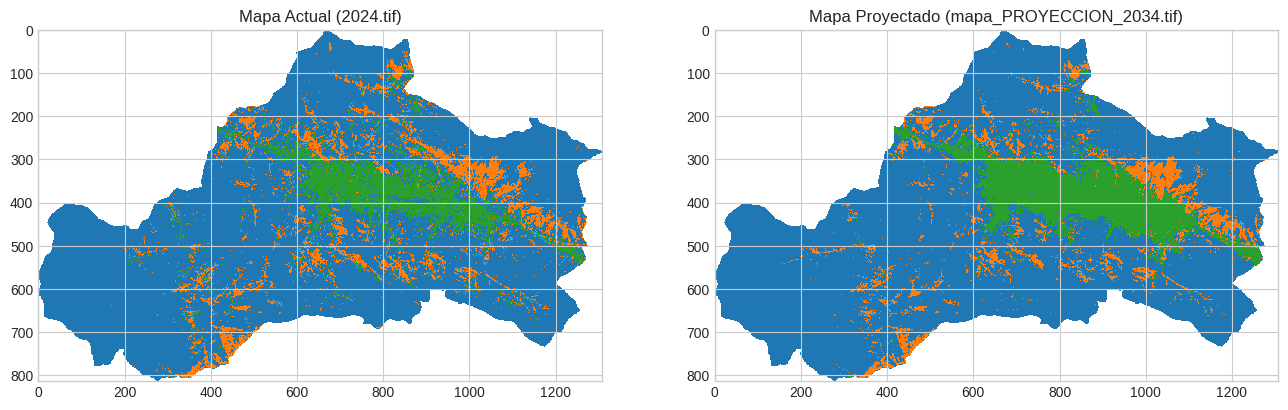

In [ ]:
# Cell 10: Phase 2C - Visualization of Projected Future
try:
    print("======================================================================")
    print(" FASE 2C: VISUALIZACIÓN DEL ESCENARIO FUTURO (2034) ")
    print("======================================================================")

    if 'predicted_raster_futuro' not in locals():
        raise NameError("No se encontró el mapa proyectado. Ejecuta la celda anterior.")

    # --- VISUALIZACIÓN COMPARATIVA ---
    print("--- Comparación Visual: Mapa Actual (2024) vs. Mapa Proyectado (2034) ---")

    # Reutilizamos la configuración de colores de celdas anteriores
    clases = crosstable_proyeccion.graduation_x
    colores = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728', '#9467bd']
    cmap_discreto = ListedColormap(colores[:len(clases)])
    bounds = [c - 0.5 for c in clases] + [clases[-1] + 0.5]
    norm = BoundaryNorm(bounds, cmap_discreto.N)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    # Mapa de partida (Real 2024)
    ax1.imshow(anho_2024.getBand(1), cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax1.set_title(f'Mapa Actual ({os.path.basename(rutas["anho_2024"])})')

    # Mapa proyectado (Simulado 2034)
    ax2.imshow(predicted_raster_futuro.getBand(1), cmap=cmap_discreto, norm=norm, interpolation='nearest')
    ax2.set_title(f'Mapa Proyectado ({os.path.basename(rutas["salida_proyeccion"])})')

    plt.show()

except Exception as e:
    print(f"\n!!!!!!  OCURRIÓ UN ERROR DURANTE LA VISUALIZACIÓN FINAL !!!!!!")
    import traceback
    traceback.print_exc()

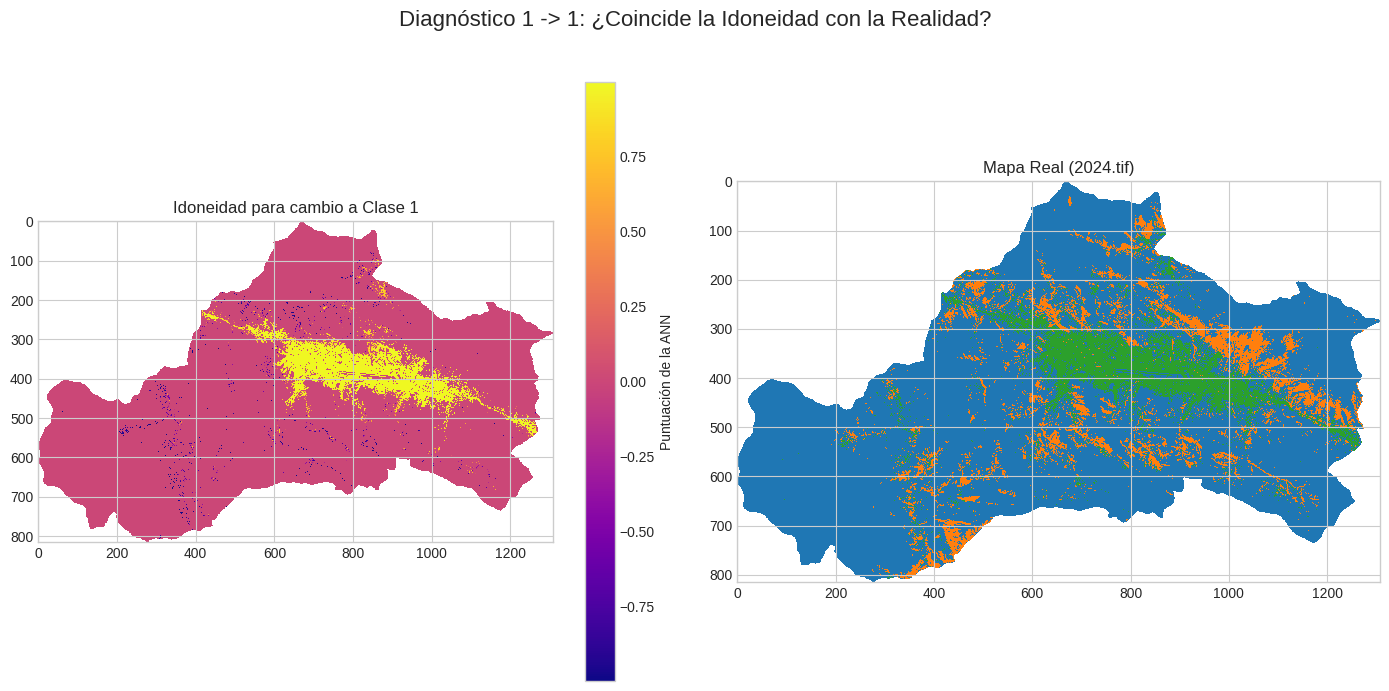

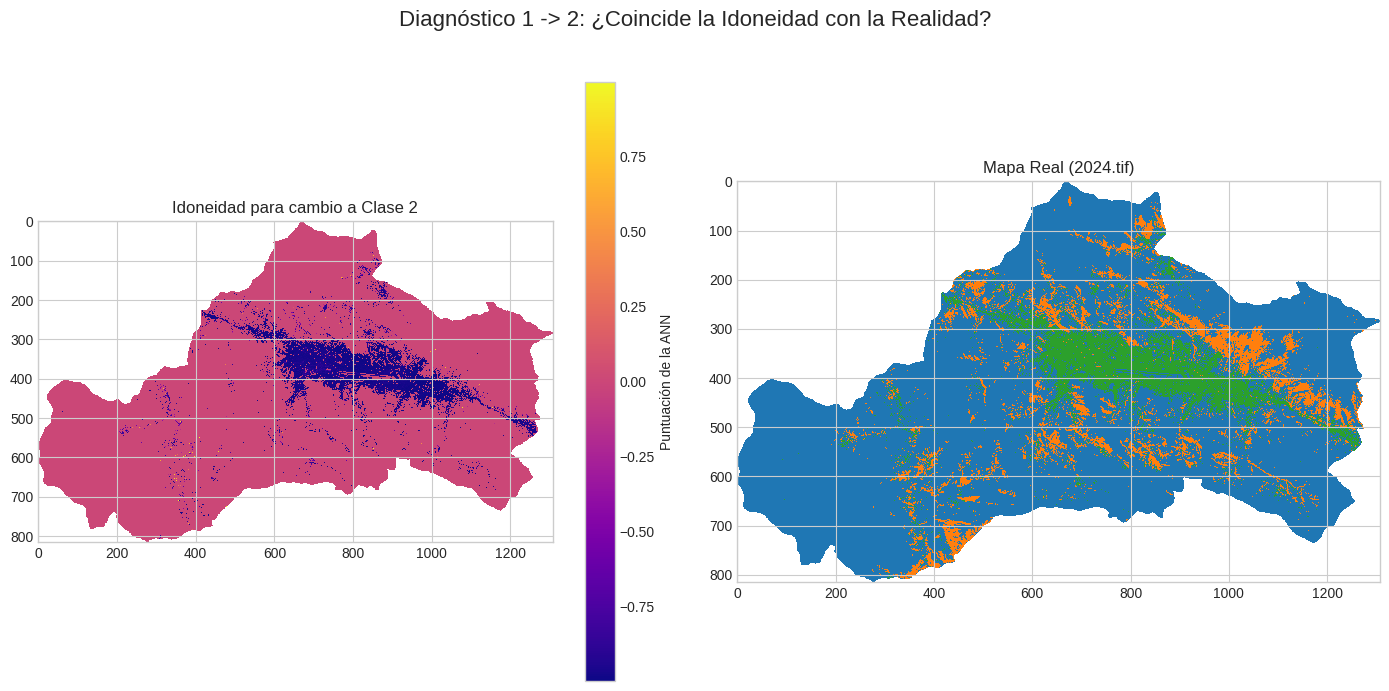

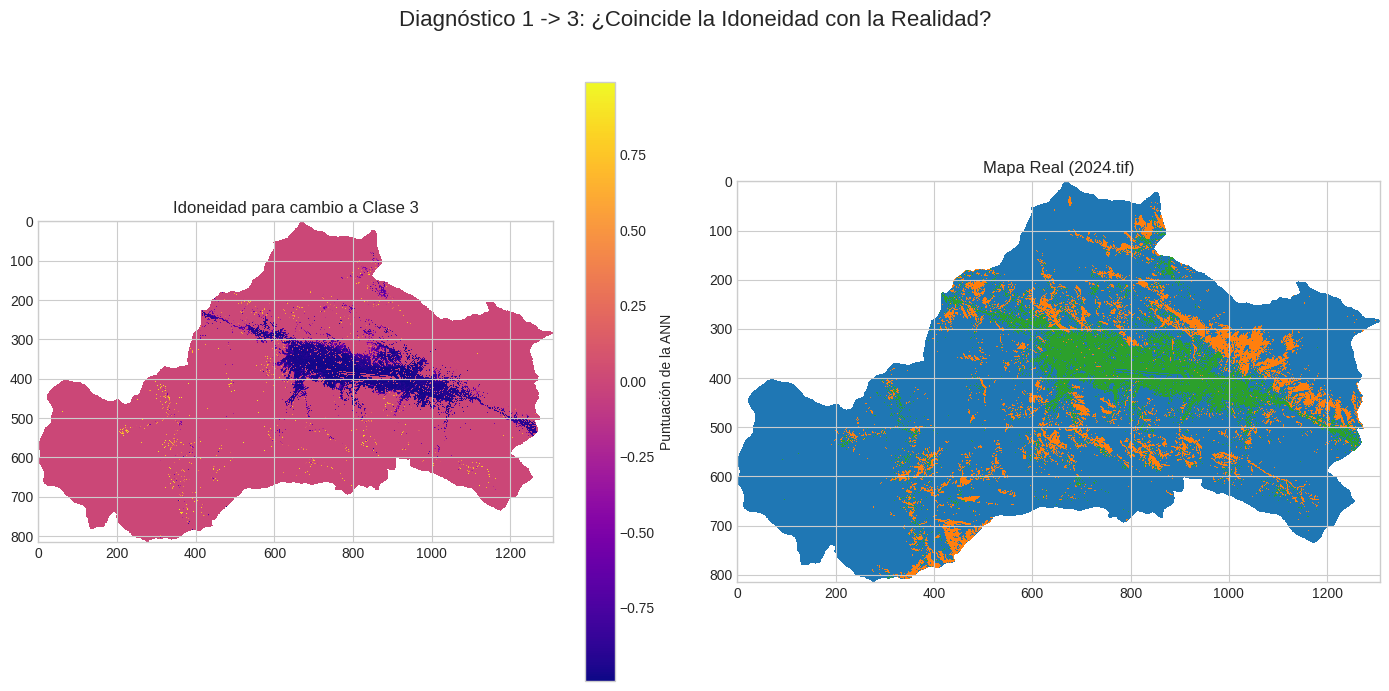

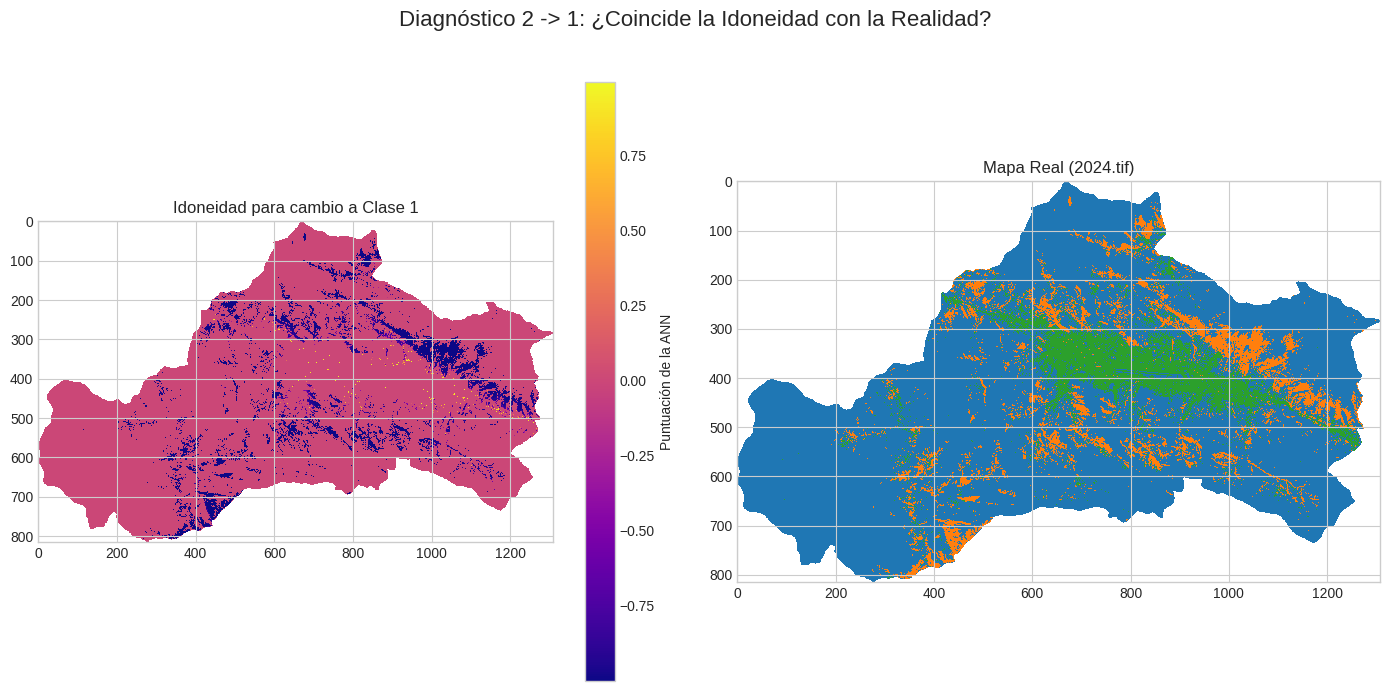

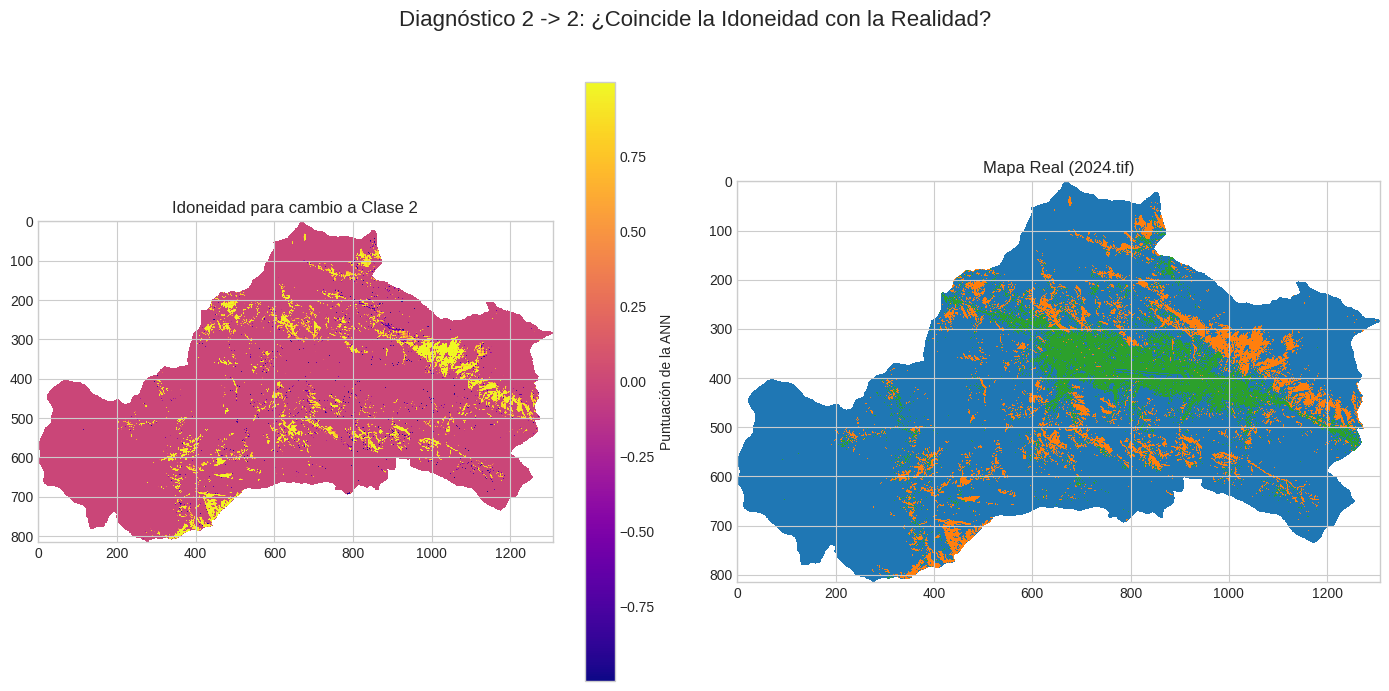

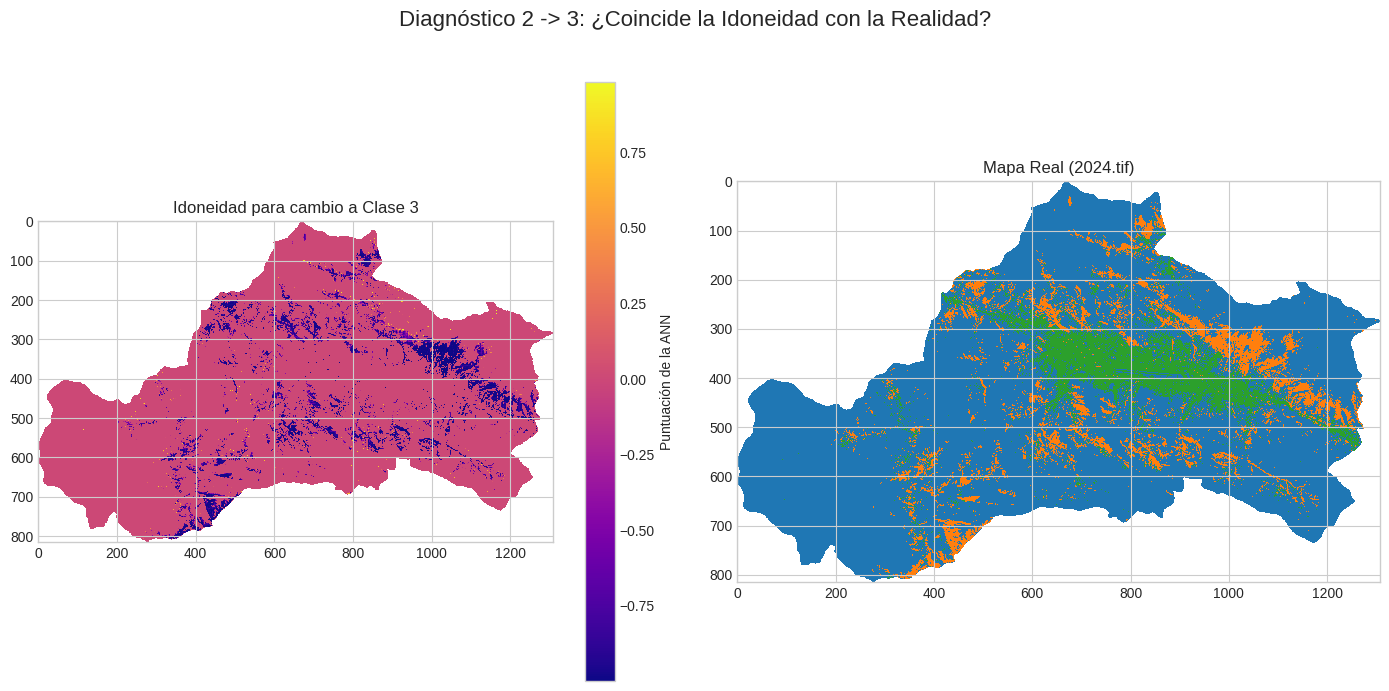

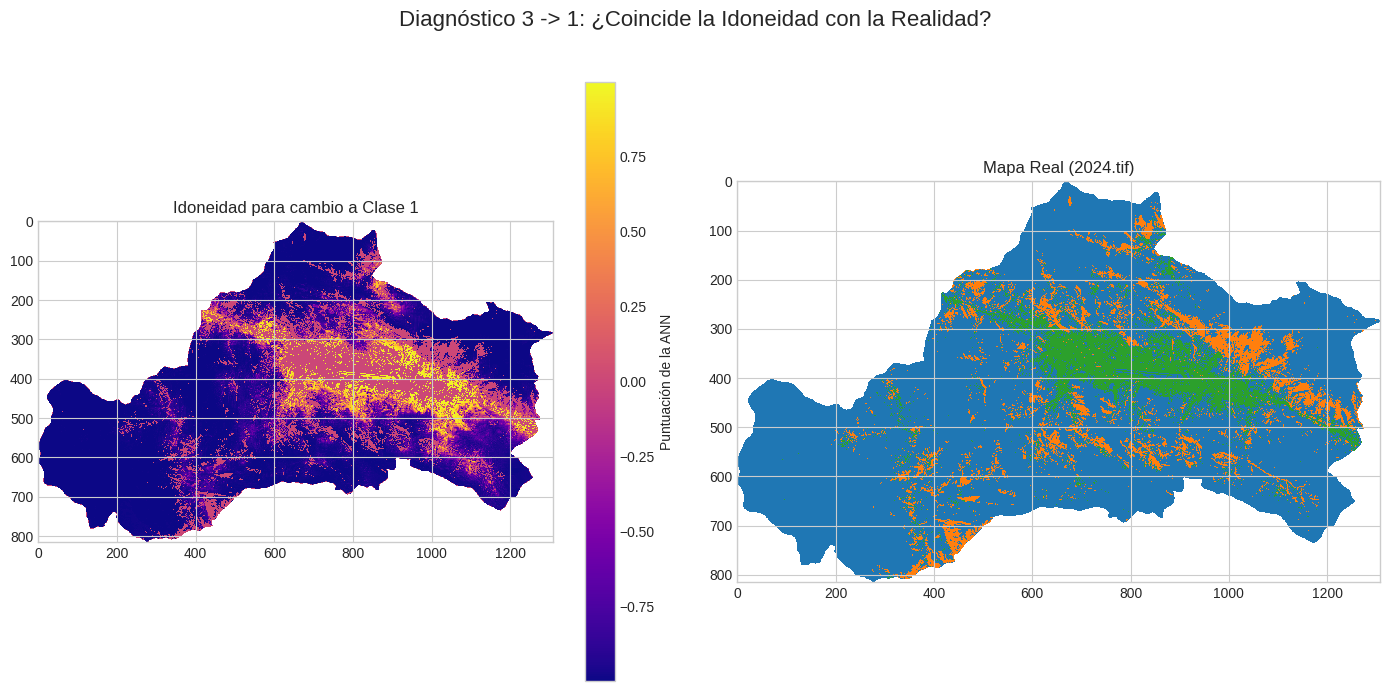

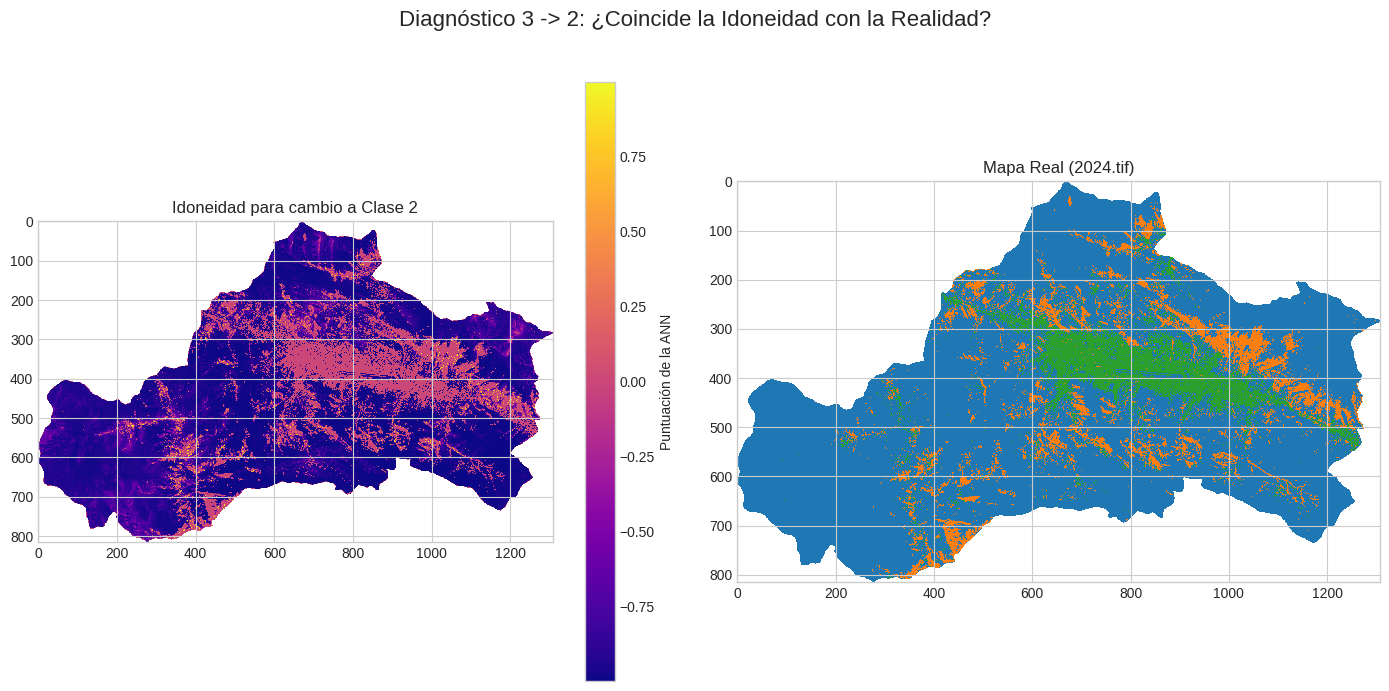

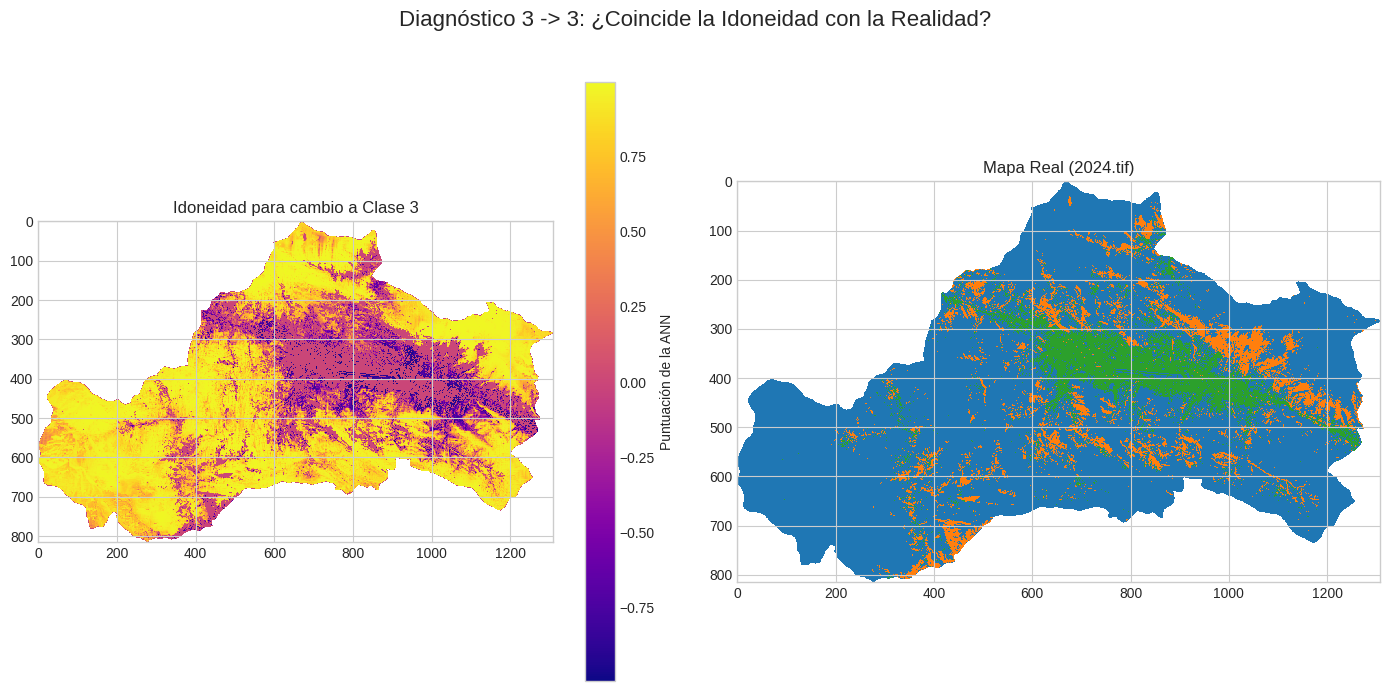

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
# Assuming that 'Raster' is a class defined in your environment (for example, from pycax).
# from pycax.raster import Raster # Descomenta si usas pycax

print("--- ANÁLISIS VISUAL DE LA PREDICCIÓN (TODAS LAS TRANSICIONES) ---")

# Las clases van de 1 a 3.
clases = range(1, 4)

# Bucle sobre todas las clases de origen
for clase_origen_a_inspeccionar in clases:
    # Bucle sobre todas las clases de destino
    for clase_destino_a_inspeccionar in clases:

        # Opcional: Saltar la transición a sí mismo (clase_origen -> misma clase_destino),
        # ya que el mapa de idoneidad para "permanecer" a menudo no es el foco del análisis.
        # if clase_origen_a_inspeccionar == clase_destino_a_inspeccionar:
        #     continue

        print(f"\n====================================================")
        print(f"ANÁLISIS DE TRANSICIÓN: {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}")
        print(f"====================================================")

        try:
            # 1. Preparar el mapa de idoneidad para la transición seleccionada
            print(f"Generando mapa de idoneidad para la transición {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}...")

            # El mapa de potencial relevante
            # ¡ADVERTENCIA! Se asume que potential_maps_validacion[clase_destino_a_inspeccionar] exists.
            mapa_de_potencial = potential_maps_futuro[clase_destino_a_inspeccionar]

            # El mapa de idoneidad solo debe mostrar valores para los píxeles que eran la clase de origen en el mapa de partida
            mapa_de_partida_array = anho_2024.getBand(1)
            candidate_pixels_mask = (mapa_de_partida_array.data == clase_origen_a_inspeccionar)

            suitability_map = mapa_de_potencial * candidate_pixels_mask
            suitability_map[mapa_de_partida_array.mask] = np.nan # Usar NaN para NoData para que se vea transparente

            # 2. Cargar el mapa real de 2024
            # ¡ADVERTENCIA! Se asume que 'Raster', 'rutas', 'cmap_discreto', y 'norm' están definidos.
            if 'real_2024_raster' not in locals():
                real_2024_raster = Raster(rutas["anho_2024"])
            real_2024_data = real_2024_raster.getBand(1)

            # --- GRÁFICO: Idoneidad vs. Mapa Real 2024 ---
            print("Mostrando Gráfico: Idoneidad vs. Realidad")
            fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
            fig1.suptitle(f'Diagnóstico {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}: ¿Coincide la Idoneidad con la Realidad?', fontsize=16)

            # Gráfico 1a: Mapa de Idoneidad
            im1 = ax1.imshow(suitability_map, cmap='plasma', interpolation='nearest')
            ax1.set_title(f'Idoneidad para cambio a Clase {clase_destino_a_inspeccionar}')
            fig1.colorbar(im1, ax=ax1, label='Puntuación de la ANN')

            # Gráfico 1b: Mapa Real 2024
            ax2.imshow(real_2024_data, cmap=cmap_discreto, norm=norm, interpolation='nearest')
            ax2.set_title(f'Mapa Real ({os.path.basename(rutas["anho_2024"])})')

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show() # Muestra el gráfico y pasa a la siguiente iteración.

        except KeyError as e:
            print(f"\n!!!!! ERROR: La clave {e} no se encontró en el diccionario 'potential_maps_validacion'. Asegúrate de que existe el mapa de potencial para la clase {clase_destino_a_inspeccionar}.")
            # Se imprime el traceback completo en el error genérico
        except Exception as e:
            print(f"\n!!!!!! OCURRIÓ UN ERROR DURANTE LA VISUALIZACIÓN DE DIAGNÓSTICO para {clase_origen_a_inspeccionar} -> {clase_destino_a_inspeccionar}!!!!!!")
            import traceback
            traceback.print_exc()